In [1]:
import os, sys, json, time, math, random, platform, warnings, zlib
from pathlib import Path

In [2]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display
from PIL import Image

In [3]:
%matplotlib inline
from skimage.color import rgb2gray
from skimage.transform import resize as sk_resize
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay)

In [4]:
try:
    import qiskit
    QISKIT_VERSION = qiskit.__version__
    from qiskit import QuantumCircuit, transpile
    from qiskit.quantum_info import Statevector
    QISKIT_OK = True
except Exception as exc:                                   
    QISKIT_VERSION, QISKIT_OK = None, False
    print("Qiskit unavailable - circuit verification/resource cells will be skipped (not_run):", repr(exc))

In [5]:
try:
    from qiskit_aer import AerSimulator
    AER_OK = True
except Exception:
    AerSimulator, AER_OK = None, False

In [6]:
try:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats("retina")
except Exception as exc:
    print("Retina inline output unavailable:", repr(exc))
mpl.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.facecolor": "white",
                     "figure.facecolor": "white", "font.size": 13, "axes.titlesize": 14, "axes.titleweight": "bold",
                     "axes.labelsize": 13, "legend.fontsize": 11, "figure.titlesize": 18, "figure.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42})
warnings.filterwarnings("ignore", category=ConvergenceWarning)

In [7]:
RUN_MODE = "smoke"         
SEED = 42
RES_LIST = [4, 8]           
MAIN_SHOTS = 8192
SHOTS_SWEEP = [256, 1024, 4096, 16384]
READOUT_SWEEP = [0.0, 0.01, 0.03]       
SWEEP_RES = 8
ROI_MARGIN = 0.15                      
FEATURE_FAMILIES = ["decoded", "histogram"]
MAX_HIST_DIM = 5000 if RUN_MODE == "paper" else 20000                    
MAIN_CLASSIFIERS = ["logreg", "svm_rbf"]
C_GRID = {"logreg": [0.01, 0.1, 1.0, 10.0], "svm_rbf": [0.1, 1.0, 10.0]}
HIST_C_GRID = [0.01, 0.1, 1.0]
BIT_DEPTH = 8
Q_CONFIG = {"smoke": dict(train_cap=500, val_cap=200, test_cap=300, seeds=[42]),
            "full": dict(train_cap=3000, val_cap=1000, test_cap=2000, seeds=[42, 43, 44]),
            "paper": dict(train_cap=None, val_cap=None, test_cap=None, seeds=[42, 43, 44])}[RUN_MODE]
N_CIRCUIT_PROBES = 5                

In [8]:
def detect_project_dir():
    if os.environ.get("QIP_PROJECT_DIR"):
        return Path(os.environ["QIP_PROJECT_DIR"])
    try:
        from google.colab import drive
        drive.mount("/content/drive"); return Path("/content/drive/MyDrive/Hybrid_QIP")
    except Exception:
        pass
    windows_default = Path(r"C:\Users\sripo\OneDrive\Desktop\Hybrid_QIP")
    return windows_default if windows_default.exists() else Path.cwd() / "Hybrid_QIP"
PROJECT_DIR = detect_project_dir()               
DATA_DIR = PROJECT_DIR / "data"                         
RESULTS_DIR = PROJECT_DIR / f"results_quantum_{RUN_MODE}"
FIG_DIR = RESULTS_DIR / "figures"
for folder in (RESULTS_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

In [9]:
def save_fig(fig, name, dpi=300):
    png = FIG_DIR / f"{name}.png"
    fig.savefig(png, dpi=dpi, bbox_inches="tight", facecolor="white"); fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight", facecolor="white")
    with Image.open(png) as im:
        print(f"Saved {name}.png: {im.size[0]} x {im.size[1]} px at {dpi} dpi (+ PDF)")

print("Python", platform.python_version(), "| NumPy", np.__version__, "| Qiskit:", QISKIT_VERSION, "| Aer:", AER_OK, "| mode:", RUN_MODE)
print("Q_CONFIG:", Q_CONFIG, "| RES_LIST:", RES_LIST)

Python 3.12.13 | NumPy 2.5.3 | Qiskit: 2.5.2 | Aer: True | mode: smoke
Q_CONFIG: {'train_cap': 500, 'val_cap': 200, 'test_cap': 300, 'seeds': [42]} | RES_LIST: [4, 8]


In [10]:
def load_seg_dataset(path):
    with np.load(path, allow_pickle=False) as z:
        data = {k: z[k] for k in z.files}
    data["meta"] = json.loads(str(data.pop("meta_json")))
    data["class_names"] = {int(k): v for k, v in data["meta"]["class_names"].items()}
    data["class_ids"] = sorted(data["class_names"])
    return data

In [11]:
def stratified_cap(labels, cap, seed):
    n = len(labels)
    if cap is None or cap >= n:
        return np.arange(n)
    rng = np.random.default_rng(seed)
    classes = np.unique(labels); per_class_min = max(1, cap // (4 * len(classes))); chosen = []
    for c in classes:
        ids = np.flatnonzero(labels == c)
        chosen.extend(rng.choice(ids, size=min(len(ids), per_class_min), replace=False).tolist())
    remaining = np.setdiff1d(np.arange(n), np.array(chosen, dtype=int))
    chosen.extend(rng.choice(remaining, size=min(cap - len(chosen), len(remaining)), replace=False).tolist())
    return np.array(sorted(chosen), dtype=int)

In [12]:
DATASET_FILES = {"derma": DATA_DIR / "derma" / "derma_ham10000_128.npz", "blood": DATA_DIR / "blood" / "blood_pbc_128.npz"}
ROI_DIR = DATA_DIR / "roi"
DATASETS_Q, NOT_RUN = {}, []
for key, path in DATASET_FILES.items():
    if not path.exists():
        NOT_RUN.append({"item": f"dataset {key}", "reason": f"{path} not found - build it with Seg_Cls_Derma_Blood.ipynb first"})
        print(f"NOT AVAILABLE: {key} ({path})"); continue
    raw = load_seg_dataset(path)
    idx = {}
    for k, split in enumerate(("train", "val", "test")):
        split_idx = np.flatnonzero(raw["split"] == split)
        idx[split] = split_idx[stratified_cap(raw["labels"][split_idx], Q_CONFIG[f"{split}_cap"], SEED + k)]
    pred_path = ROI_DIR / f"{key}_pred_boxes.npz"
    pred_lookup, pred_meta = {}, None
    if pred_path.exists():
        with np.load(pred_path, allow_pickle=False) as z:
            pred_lookup = {str(s): tuple(int(v) for v in b) for s, b in zip(z["sample_id"], z["pred_boxes"])}
            pred_meta = json.loads(str(z["meta_json"]))
        print(f"{key}: predicted boxes for {len(pred_lookup)} images (segmentation run_mode = {pred_meta.get('run_mode')})")
        if pred_meta.get("run_mode") == "smoke":
            print(f"  WARNING: {key} boxes come from a SMOKE-trained segmentation model (a few epochs on tiny subsets); pred_box results are only a plumbing test.")
    else:
        NOT_RUN.append({"item": f"{key}: pred_box ROI", "reason": f"{pred_path.name} missing - run the 'export ROI boxes' cell of the segmentation notebook after training"})
        print(f"{key}: no predicted-box file ({pred_path.name}); pred_box experiments will be recorded as not_run.")
    DATASETS_Q[key] = {"name": key, "raw": raw, "idx": idx, "pred_lookup": pred_lookup, "pred_meta": pred_meta,
                       "class_ids": raw["class_ids"], "class_names": raw["class_names"]}
    print(key, {s: len(i) for s, i in idx.items()}, "| image size:", raw["images"].shape[1:])
if not DATASETS_Q:
    raise RuntimeError("No dataset found under data/. Run Seg_Cls_Derma_Blood.ipynb first (same project folder).")

derma: predicted boxes for 3006 images (segmentation run_mode = smoke)
derma {'train': 500, 'val': 200, 'test': 300} | image size: (128, 128, 3)
blood: predicted boxes for 5133 images (segmentation run_mode = smoke)
blood {'train': 500, 'val': 200, 'test': 300} | image size: (128, 128, 3)


In [13]:
def box_iou(a, b):
    if a is None or b is None: return 0.0
    iw = max(0, min(a[2], b[2]) - max(a[0], b[0])); ih = max(0, min(a[3], b[3]) - max(a[1], b[1])); inter = iw * ih
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0

In [14]:
def square_crop(image, box, margin=ROI_MARGIN, min_side=8):
    """Square crop centred on the box (side = longest box side * (1 + 2*margin)), edge-padded if it leaves the image.
    Returns (crop, used_box). box=None -> whole image (fallback)."""
    if box is None or box[0] < 0 or box[2] <= box[0] or box[3] <= box[1]:
        return image, False
    h, w = image.shape[:2]
    x0, y0, x1, y1 = box
    cx, cy = (x0 + x1) / 2.0, (y0 + y1) / 2.0
    side = max(int(round(max(x1 - x0, y1 - y0) * (1 + 2 * margin))), min_side)
    left, top = int(round(cx - side / 2.0)), int(round(cy - side / 2.0))
    pad = max(0, -left, -top, left + side - w, top + side - h)
    if pad > 0:
        image = np.pad(image, ((pad, pad), (pad, pad), (0, 0)), mode="edge"); left += pad; top += pad
    return image[top:top + side, left:left + side], True

In [15]:
def to_gray_uint8(crop, res):
    gray = rgb2gray(crop)                                                  # luminance, float in [0, 1]
    small = sk_resize(gray, (res, res), anti_aliasing=True, preserve_range=True)
    return np.clip(np.rint(small * 255.0), 0, 255).astype(np.uint8)

In [16]:
def to_rgb_uint8(crop, res):
    small = sk_resize(crop.astype(np.float64), (res, res, 3), anti_aliasing=True, preserve_range=True)
    return np.clip(np.rint(small), 0, 255).astype(np.uint8)

In [17]:
_ROI_CACHE = {}
def roi_stack(d, split, source, res, rgb=False):
    """Array of ROI images (N,res,res[,3]) uint8 for a split, plus the fraction of images that fell back to the full image."""
    cache_key = (d["name"], split, source, res, rgb)
    if cache_key in _ROI_CACHE:
        return _ROI_CACHE[cache_key]
    raw, ids = d["raw"], d["idx"][split]
    out, fallbacks = [], 0
    for i in ids:
        image = raw["images"][i]
        if source == "full_image":
            box = None
        elif source == "gt_box":
            box = tuple(int(v) for v in raw["boxes"][i]) if raw["has_mask"][i] else None
        elif source == "pred_box":
            box = d["pred_lookup"].get(str(raw["sample_id"][i]))
        else:
            raise ValueError(source)
        crop, used = square_crop(image, box)
        fallbacks += (0 if (used or source == "full_image") else 1)
        out.append(to_rgb_uint8(crop, res) if rgb else to_gray_uint8(crop, res))
    result = (np.stack(out), fallbacks / max(len(ids), 1))
    _ROI_CACHE[cache_key] = result
    return result

In [18]:
_img = np.zeros((128, 128, 3), np.uint8); _img[40:80, 30:100] = 200
_crop, _used = square_crop(_img, (30, 40, 100, 80)); assert _used and _crop.shape[0] == _crop.shape[1] == int(round(70 * 1.3)), _crop.shape
_crop, _used = square_crop(_img, (0, 0, 20, 20)); assert _used and _crop.shape[0] == _crop.shape[1], "edge crop must stay square"
_crop, _used = square_crop(_img, None); assert (not _used) and _crop.shape == _img.shape
assert to_gray_uint8(_img, 8).shape == (8, 8) and to_rgb_uint8(_img, 4).shape == (4, 4, 3)
print("ROI cropping tests passed.")

ROI cropping tests passed.


In [19]:
def n_position_qubits(side):
    n_pos = int(round(2 * math.log2(side)))
    assert side >= 2 and 2 ** n_pos == side * side, "side must be a power of two"
    return n_pos

In [20]:
def frqi_state(image):
    flat = np.asarray(image, dtype=np.uint8).reshape(-1); n = flat.size
    theta = (np.pi / 2.0) * flat.astype(np.float64) / 255.0
    state = np.zeros(2 * n); state[0::2] = np.cos(theta) / math.sqrt(n); state[1::2] = np.sin(theta) / math.sqrt(n)
    return state

In [21]:
def neqr_state(image, bit_depth=BIT_DEPTH):
    flat = np.asarray(image, dtype=np.uint8).reshape(-1); n = flat.size; n_pos = n_position_qubits(int(round(math.sqrt(n))))
    state = np.zeros((2 ** bit_depth) * n)
    state[(flat.astype(np.int64) << n_pos) | np.arange(n)] = 1.0 / math.sqrt(n)
    return state

In [22]:
def frqi_reconstruct(state, shape):
    n = shape[0] * shape[1]
    theta = np.arctan2(np.abs(state[1::2][:n]), np.abs(state[0::2][:n]))
    return np.clip(np.rint(255.0 * 2.0 * theta / np.pi), 0, 255).astype(np.uint8).reshape(shape)

In [23]:
def neqr_state(image, bit_depth=BIT_DEPTH):
    flat = np.asarray(image, dtype=np.uint8).reshape(-1); n = flat.size; n_pos = n_position_qubits(int(round(math.sqrt(n))))
    state = np.zeros((2 ** bit_depth) * n)
    state[(flat.astype(np.int64) << n_pos) | np.arange(n)] = 1.0 / math.sqrt(n)
    return state

In [24]:
def frqi_reconstruct(state, shape):
    n = shape[0] * shape[1]
    theta = np.arctan2(np.abs(state[1::2][:n]), np.abs(state[0::2][:n]))
    return np.clip(np.rint(255.0 * 2.0 * theta / np.pi), 0, 255).astype(np.uint8).reshape(shape)

In [25]:
def neqr_reconstruct(state, shape, bit_depth=BIT_DEPTH):
    n = shape[0] * shape[1]
    return np.argmax(np.abs(state).reshape(2 ** bit_depth, n), axis=0).astype(np.uint8).reshape(shape)

In [26]:
def born_probabilities(image, encoding):
    """|amplitude|^2 without building a complex state (identical to |state|^2; verified below)."""
    flat = np.asarray(image, dtype=np.uint8).reshape(-1); n = flat.size
    if encoding == "FRQI":
        theta = (np.pi / 2.0) * flat.astype(np.float64) / 255.0
        p = np.zeros(2 * n); p[0::2] = np.cos(theta) ** 2 / n; p[1::2] = np.sin(theta) ** 2 / n
        return p
    if encoding == "NEQR":
        n_pos = n_position_qubits(int(round(math.sqrt(n))))
        p = np.zeros((2 ** BIT_DEPTH) * n); p[(flat.astype(np.int64) << n_pos) | np.arange(n)] = 1.0 / n
        return p
    raise ValueError(encoding)

In [27]:
def n_qubits_for(encoding, side):
    return n_position_qubits(side) + (1 if encoding == "FRQI" else BIT_DEPTH)

In [28]:
manual = {"all_zero": np.zeros((2, 2), np.uint8), "all_255": np.full((2, 2), 255, np.uint8), "mixed": np.array([[0, 85], [170, 255]], np.uint8)}
for name, im in manual.items():
    for enc, state_fn, rec_fn in (("FRQI", frqi_state, frqi_reconstruct), ("NEQR", neqr_state, neqr_reconstruct)):
        st = state_fn(im)
        assert abs(np.sum(st ** 2) - 1.0) < 1e-12, (name, enc, "normalisation")
        assert len(st) == 2 ** n_qubits_for(enc, 2), (name, enc, "dimension")
        assert np.array_equal(rec_fn(st, im.shape), im), (name, enc, "reconstruction")
        assert np.allclose(born_probabilities(im, enc), st ** 2), (name, enc, "Born probabilities")
rng_t = np.random.default_rng(0)
for side in (4, 8):
    im = rng_t.integers(0, 256, (side, side)).astype(np.uint8)
    assert np.array_equal(frqi_reconstruct(frqi_state(im), im.shape), im) and np.array_equal(neqr_reconstruct(neqr_state(im), im.shape), im)
# bit ordering: bright pixel at (row, col) of a 4x4 image must sit at a known basis index
side, row, col = 4, 2, 1; p = row * side + col; n_pos = n_position_qubits(side)
single = np.zeros((side, side), np.uint8); single[row, col] = 255
assert abs(frqi_state(single)[(p << 1) | 1] - 1 / math.sqrt(side * side)) < 1e-12
assert abs(neqr_state(single)[(255 << n_pos) | p] - 1 / math.sqrt(side * side)) < 1e-12
print("FRQI/NEQR state-vector tests passed (normalisation, dimension, exact reconstruction, bit ordering).")
print("Qubits: " + ", ".join(f"{r}x{r}: FRQI {n_qubits_for('FRQI', r)} / NEQR {n_qubits_for('NEQR', r)}" for r in (2, 4, 8, 16)))
print("State-vector memory (float64 amplitudes): " + ", ".join(f"NEQR {r}x{r}: {8 * 2 ** n_qubits_for('NEQR', r) / 2 ** 20:.3f} MiB" for r in (4, 8, 16)))

FRQI/NEQR state-vector tests passed (normalisation, dimension, exact reconstruction, bit ordering).
Qubits: 2x2: FRQI 3 / NEQR 10, 4x4: FRQI 5 / NEQR 12, 8x8: FRQI 7 / NEQR 14, 16x16: FRQI 9 / NEQR 16
State-vector memory (float64 amplitudes): NEQR 4x4: 0.031 MiB, NEQR 8x8: 0.125 MiB, NEQR 16x16: 0.500 MiB


In [29]:
def apply_readout_error(prob, n_qubits, e):
    """Exact distribution after independent symmetric bit flips (probability e) on every measured qubit."""
    if e == 0:
        return prob
    kernel = np.array([[1 - e, e], [e, 1 - e]])
    p = prob.reshape((2,) * n_qubits)
    for axis in range(n_qubits):
        p = np.moveaxis(np.tensordot(kernel, p, axes=([1], [axis])), 0, axis)
    return p.reshape(-1)

In [30]:
def decode_frqi_counts(counts, side):
    """Per-pixel intensity from colour-qubit outcomes; Laplace smoothing => unobserved positions decode to mid-gray."""
    n = side * side
    c0, c1 = counts[0::2][:n].astype(np.float64), counts[1::2][:n].astype(np.float64)
    p1 = (c1 + 0.5) / (c0 + c1 + 1.0)
    theta = np.arcsin(np.sqrt(np.clip(p1, 0.0, 1.0)))
    unobserved = float(np.mean((c0 + c1) == 0))
    return np.clip(np.rint(255.0 * 2.0 * theta / np.pi), 0, 255).astype(np.uint8).reshape(side, side), unobserved

In [31]:
def decode_neqr_counts(counts, side):
    """Per-pixel intensity = most frequent intensity observed at that position (majority vote); unobserved -> 127."""
    n = side * side
    table = counts.reshape(2 ** BIT_DEPTH, n)
    totals = table.sum(axis=0)
    image = np.where(totals > 0, np.argmax(table, axis=0), 127).astype(np.uint8)
    return image.reshape(side, side), float(np.mean(totals == 0))

In [32]:
def sample_counts(image, encoding, shots, readout, rng):
    side = image.shape[0]
    probs = apply_readout_error(born_probabilities(image, encoding), n_qubits_for(encoding, side), readout)
    return rng.multinomial(shots, probs / probs.sum())

In [33]:
n_t, e_t = 4, 0.07
p_t = np.random.default_rng(1).dirichlet(np.ones(2 ** n_t))
brute = np.array([sum(p_t[x] * (1 - e_t) ** (n_t - bin(x ^ y).count("1")) * e_t ** bin(x ^ y).count("1") for x in range(2 ** n_t)) for y in range(2 ** n_t)])
assert np.allclose(apply_readout_error(p_t, n_t, e_t), brute) and abs(brute.sum() - 1) < 1e-12
# (2) noiseless, many shots: NEQR decodes exactly; FRQI error is small and shrinks with shots
img_t = np.random.default_rng(2).integers(0, 256, (8, 8)).astype(np.uint8)
rng_m = np.random.default_rng(3)
dec, unobs = decode_neqr_counts(sample_counts(img_t, "NEQR", 65536, 0.0, rng_m), 8)
assert np.array_equal(dec, img_t) and unobs == 0.0
errs = []
for shots in (512, 8192, 131072):
    d_f, _ = decode_frqi_counts(sample_counts(img_t, "FRQI", shots, 0.0, rng_m), 8); errs.append(float(np.mean((d_f.astype(float) - img_t) ** 2)))
assert errs[0] > errs[2], errs
# (3) readout error on the colour qubit biases FRQI decoding (p1' = e + (1-2e) p1), so its error must grow with e even at huge shot counts
mse_f = lambda e: float(np.mean((decode_frqi_counts(sample_counts(img_t, "FRQI", 131072, e, rng_m), 8)[0].astype(float) - img_t) ** 2))
assert mse_f(0.05) > 10 * mse_f(0.0), (mse_f(0.0), mse_f(0.05))
# (4) NEQR majority-vote decoding, by contrast, is expected to survive small readout error when every position receives many shots
d_n, _ = decode_neqr_counts(sample_counts(img_t, "NEQR", 65536, 0.01, rng_m), 8)
print("NEQR pixel error rate at 1% readout error, 65536 shots (majority-vote decode):", float(np.mean(d_n != img_t)))
print("Measurement-model tests passed. FRQI MSE vs shots (512/8192/131072):", [round(e, 2) for e in errs])

NEQR pixel error rate at 1% readout error, 65536 shots (majority-vote decode): 0.0
Measurement-model tests passed. FRQI MSE vs shots (512/8192/131072): [827.23, 55.95, 3.39]


In [34]:
def _toggle_flips(pixel_index, position_qubits, flipped):
    ops = []
    for bit, qubit in enumerate(position_qubits):
        needs = not ((pixel_index >> bit) & 1)            # position bit 0 -> X so that all-ones means "position == pixel_index"
        if needs != flipped[bit]:
            ops.append(("x", qubit)); flipped[bit] = needs
    return ops

In [35]:
def frqi_ops(image):
    flat = np.asarray(image, dtype=np.uint8).reshape(-1); n_pos = n_position_qubits(int(round(math.sqrt(flat.size))))
    colour, pos_q = 0, list(range(1, n_pos + 1))                      # qubit 0 = colour, qubits 1..n_pos = position bits 0..n_pos-1
    ops, flipped = [("h", q) for q in pos_q], [False] * n_pos
    for p, g in enumerate(flat):
        if g == 0:
            continue                                                  # theta = 0 -> identity
        theta = (np.pi / 2.0) * float(g) / 255.0
        ops += _toggle_flips(p, pos_q, flipped)
        ops += [("ry", theta, colour), ("mcx", tuple(pos_q), colour), ("ry", -theta, colour), ("mcx", tuple(pos_q), colour)]   # = controlled-RY(2*theta)
    ops += [("x", pos_q[b]) for b in range(n_pos) if flipped[b]]
    return ops, 1 + n_pos

In [36]:
def neqr_ops(image):
    flat = np.asarray(image, dtype=np.uint8).reshape(-1); n_pos = n_position_qubits(int(round(math.sqrt(flat.size))))
    pos_q = list(range(n_pos))                                        # qubits 0..n_pos-1 = position, then 8 intensity qubits (LSB first)
    ops, flipped = [("h", q) for q in pos_q], [False] * n_pos
    for p, g in enumerate(flat):
        bits = [b for b in range(BIT_DEPTH) if (int(g) >> b) & 1]
        if not bits:
            continue
        ops += _toggle_flips(p, pos_q, flipped)
        ops += [("mcx", tuple(pos_q), n_pos + b) for b in bits]
    ops += [("x", pos_q[b]) for b in range(n_pos) if flipped[b]]
    return ops, n_pos + BIT_DEPTH

In [37]:
def build_circuit(image, encoding):
    ops, n_qubits = frqi_ops(image) if encoding == "FRQI" else neqr_ops(image)
    qc = QuantumCircuit(n_qubits, name=f"{encoding}_{image.shape[0]}x{image.shape[1]}")
    for op in ops:
        if op[0] == "h": qc.h(op[1])
        elif op[0] == "x": qc.x(op[1])
        elif op[0] == "ry": qc.ry(op[1], op[2])
        elif op[0] == "mcx": qc.mcx(list(op[1]), op[2])
    return qc, ops

In [38]:
circuit_rows, resource_rows = [], []
if not QISKIT_OK:
    NOT_RUN.append({"item": "circuit verification + resource measurement", "reason": "Qiskit not installed/importable"})
    print("Circuit verification NOT RUN (Qiskit unavailable).")
else:
    first = next(iter(DATASETS_Q.values()))
    for res in RES_LIST:
        probe_images, _ = roi_stack(first, "test", "gt_box", res)
        probe_images = probe_images[:N_CIRCUIT_PROBES]
        for encoding in ("FRQI", "NEQR"):
            n_qubits = n_qubits_for(encoding, res)
            for k, img in enumerate(probe_images):
                try:
                    t0 = time.perf_counter(); qc, ops = build_circuit(img, encoding); build_s = time.perf_counter() - t0
                    row = {"image_size": res, "encoding": encoding, "image_index": k, "logical_qubits": qc.num_qubits,
                           "logical_mcx": sum(o[0] == "mcx" for o in ops), "build_seconds": build_s}
                    if n_qubits <= 14:                                # exact simulation of the circuit; 16x16 NEQR skipped (slow)
                        produced = np.asarray(Statevector(qc).data)
                        target = frqi_state(img) if encoding == "FRQI" else neqr_state(img)
                        row.update({"state_fidelity": float(abs(np.vdot(target, produced)) ** 2), "max_amplitude_error": float(np.max(np.abs(produced - target)))})
                        assert row["state_fidelity"] > 1 - 1e-9, "circuit does not reproduce the target state"
                    t1 = time.perf_counter()
                    compiled = transpile(qc, basis_gates=["u", "cx"], optimization_level=1, seed_transpiler=SEED)
                    counts = compiled.count_ops()
                    row.update({"compiled_total_gates": int(sum(counts.values())), "compiled_cx": int(counts.get("cx", 0)), "compiled_depth": int(compiled.depth()),
                                "transpile_seconds": time.perf_counter() - t1, "basis_gates": "u,cx", "optimization_level": 1, "qiskit_version": QISKIT_VERSION, "status": "measured"})
                except Exception as exc:
                    row = {"image_size": res, "encoding": encoding, "image_index": k, "status": f"failed: {type(exc).__name__}: {exc}"}
                circuit_rows.append(row)
    circuit_df = pd.DataFrame(circuit_rows)
    display(circuit_df)
    circuit_df.to_csv(RESULTS_DIR / "circuit_verification_and_resources.csv", index=False)
    ok = circuit_df["status"].eq("measured")
    print(f"{int(ok.sum())}/{len(circuit_df)} circuits built, verified (where simulated) and transpiled.")
    if "state_fidelity" in circuit_df:
        print("Minimum state fidelity vs the mathematical state:", float(circuit_df["state_fidelity"].min()))

,image_size,encoding,image_index,logical_qubits,logical_mcx,build_seconds,state_fidelity,max_amplitude_error,compiled_total_gates,compiled_cx,compiled_depth,transpile_seconds,basis_gates,optimization_level,qiskit_version,status
0,4,FRQI,0,5,32,0.001938,1.0,2.128855e-14,2430,1152,2049,1.163810,"u,cx",1,2.5.2,measured
1,4,FRQI,1,5,32,0.001242,1.0,2.156645e-14,2430,1152,2049,0.029015,"u,cx",1,2.5.2,measured
2,4,FRQI,2,5,32,0.005452,1.0,1.871286e-14,2430,1152,2049,0.127951,"u,cx",1,2.5.2,measured
3,4,FRQI,3,5,32,0.002518,1.0,2.134534e-14,2430,1152,2049,0.015792,"u,cx",1,2.5.2,measured
4,4,FRQI,4,5,32,0.001234,1.0,2.137536e-14,2430,1152,2049,0.014740,"u,cx",1,2.5.2,measured
5,4,NEQR,0,12,72,0.002099,1.0,5.376335e-14,2918,1296,2518,0.024537,"u,cx",1,2.5.2,measured
6,4,NEQR,1,12,57,0.001587,1.0,4.268899e-14,2852,1290,2438,0.018855,"u,cx",1,2.5.2,measured
7,4,NEQR,2,12,61,0.002147,1.0,4.593550e-14,3125,1418,2690,0.021911,"u,cx",1,2.5.2,measured
8,4,NEQR,3,12,55,0.001828,1.0,4.127320e-14,2870,1302,2471,0.028122,"u,cx",1,2.5.2,measured
9,4,NEQR,4,12,68,0.003922,1.0,5.054373e-14,3258,1472,2800,0.025251,"u,cx",1,2.5.2,measured


20/20 circuits built, verified (where simulated) and transpiled.
Minimum state fidelity vs the mathematical state: 0.999999999996958


In [39]:
def feature_rng(seed, tag):
    return np.random.default_rng([seed, zlib.crc32(tag.encode())])

In [40]:
def quantum_features(gray_stack, encoding, family, shots, readout, seed, tag):
    """Finite-shot measurement features for a stack of ROI images. Returns (features, per-image reconstruction MSE or NaN)."""
    side = gray_stack.shape[1]; n_qubits = n_qubits_for(encoding, side)
    dim = (side * side) if family == "decoded" else 2 ** n_qubits
    features = np.zeros((len(gray_stack), dim), np.float32); mse = np.full(len(gray_stack), np.nan)
    rng = feature_rng(seed, tag)
    for i, image in enumerate(gray_stack):
        counts = sample_counts(image, encoding, shots, readout, rng)
        if family == "histogram":
            features[i] = counts / float(shots)
        else:
            decoded, _ = (decode_frqi_counts if encoding == "FRQI" else decode_neqr_counts)(counts, side)
            features[i] = decoded.reshape(-1) / 255.0
            mse[i] = float(np.mean((decoded.astype(np.float64) - image.astype(np.float64)) ** 2))
    return features, mse

In [41]:
def multiclass_metrics(y_true, y_pred, scores, class_ids):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred); scores = np.asarray(scores, dtype=np.float64)
    aucs = []
    for column, c in enumerate(class_ids):
        positive = (y_true == c)
        if 0 < positive.sum() < len(positive):
            aucs.append(float(roc_auc_score(positive, scores[:, column])))
    return {"accuracy": float(accuracy_score(y_true, y_pred)), "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
            "macro_precision": float(precision_score(y_true, y_pred, labels=class_ids, average="macro", zero_division=0)),
            "macro_recall": float(recall_score(y_true, y_pred, labels=class_ids, average="macro", zero_division=0)),
            "macro_f1": float(f1_score(y_true, y_pred, labels=class_ids, average="macro", zero_division=0)),
            "weighted_f1": float(f1_score(y_true, y_pred, labels=class_ids, average="weighted", zero_division=0)),
            "roc_auc_ovr_macro": float(np.mean(aucs)) if aucs else np.nan}

In [42]:
def make_classifier(kind, C, seed):
    if kind == "logreg":
        est = LogisticRegression(C=C, max_iter=3000, class_weight="balanced", random_state=seed)
    elif kind == "svm_rbf":
        est = SVC(kernel="rbf", C=C, gamma="scale", class_weight="balanced", decision_function_shape="ovr", random_state=seed)
    else:
        raise ValueError(kind)
    return Pipeline([("scale", StandardScaler()), ("clf", est)])

In [43]:
def fit_select_evaluate(Xtr, ytr, Xva, yva, Xte, yte, class_ids, kind, c_grid, seed):
    """Choose C on VALIDATION macro-F1, then evaluate on TEST once. Returns (row dict, test predictions)."""
    best = None
    t0 = time.perf_counter()
    for C in c_grid:
        pipe = make_classifier(kind, C, seed).fit(Xtr, ytr)
        val_f1 = float(f1_score(yva, pipe.predict(Xva), labels=class_ids, average="macro", zero_division=0))
        if best is None or val_f1 > best[0]:
            best = (val_f1, C, pipe)
    fit_seconds = time.perf_counter() - t0
    val_f1, C, pipe = best
    assert list(pipe.named_steps["clf"].classes_) == list(class_ids), "training subset is missing a class"
    scores = pipe.predict_proba(Xte) if kind == "logreg" else pipe.decision_function(Xte)
    if scores.ndim == 1:
        scores = np.column_stack([-scores, scores])
    predictions = pipe.predict(Xte)
    return {"best_C": C, "val_macro_f1": val_f1, "fit_seconds": fit_seconds, **multiclass_metrics(yte, predictions, scores, class_ids)}, predictions

In [44]:
def paired_bootstrap_f1_diff(y, pred_a, pred_b, class_ids, n_boot=500, seed=0):
    """Mean and 95% percentile interval of macro-F1(A) - macro-F1(B) over resampled test images (same images for both)."""
    rng = np.random.default_rng(seed); n = len(y); diffs = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        diffs.append(f1_score(y[idx], pred_a[idx], labels=class_ids, average="macro", zero_division=0)
                     - f1_score(y[idx], pred_b[idx], labels=class_ids, average="macro", zero_division=0))
    return float(np.mean(diffs)), float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))

In [45]:
_r = np.random.default_rng(0); _y = _r.integers(0, 3, 300); _X = np.eye(3)[_y] * 2 + _r.normal(0, 0.3, (300, 3))
_row, _pred = fit_select_evaluate(_X[:200], _y[:200], _X[200:250], _y[200:250], _X[250:], _y[250:], [0, 1, 2], "logreg", [0.1, 1.0], 0)
assert _row["macro_f1"] > 0.9 and abs(paired_bootstrap_f1_diff(_y[250:], _pred, _pred, [0, 1, 2], 50)[0]) < 1e-12
print("Classifier pipeline self-test passed.")

Classifier pipeline self-test passed.


In [46]:
SOURCES = ["full_image", "gt_box", "pred_box"]
main_rows, PRED_STORE = [], {}

In [47]:
def base_row(d, res, test_source, train_source, enc, family, clf, shots, readout, seed, sizes, fallbacks):
    return {"dataset": d["name"], "resolution": res, "roi_test_source": test_source, "roi_train_source": train_source, "encoding": enc,
            "feature_family": family, "classifier": clf, "shots": shots, "readout_error": readout, "seed": seed,
            "n_train": sizes[0], "n_val": sizes[1], "n_test": sizes[2],
            "fallback_rate_train": fallbacks[0], "fallback_rate_val": fallbacks[1], "fallback_rate_test": fallbacks[2],
            "status": "completed", "mode": "Born-sampling simulation (no gate noise, no hardware)" if enc in ("FRQI", "NEQR") else "classical"}

In [48]:
t_main = time.perf_counter()
for key, d in DATASETS_Q.items():
    ids = d["class_ids"]; raw = d["raw"]
    ytr, yva, yte = (raw["labels"][d["idx"][s]] for s in ("train", "val", "test"))
    for res in RES_LIST:
        for test_source in SOURCES:
            if test_source == "pred_box" and not d["pred_lookup"]:
                main_rows.append({"dataset": key, "resolution": res, "roi_test_source": test_source, "status": "not_run: no predicted-box file"}); continue
            train_source = "full_image" if test_source == "full_image" else "gt_box"
            (g_tr, fb_tr), (g_va, fb_va), (g_te, fb_te) = (roi_stack(d, "train", train_source, res), roi_stack(d, "val", test_source, res), roi_stack(d, "test", test_source, res))
            sizes, fallbacks = (len(ytr), len(yva), len(yte)), (fb_tr, fb_va, fb_te)
            # ---- classical controls (no quantum step, no sampling randomness)
            for ctrl in ("classical_gray", "classical_rgb"):
                if ctrl == "classical_gray":
                    Xs = [g.reshape(len(g), -1) / 255.0 for g in (g_tr, g_va, g_te)]
                else:
                    Xs = [roi_stack(d, s, src, res, rgb=True)[0].reshape(len(idx), -1) / 255.0 for s, src, idx in
                          (("train", train_source, ytr), ("val", test_source, yva), ("test", test_source, yte))]
                for clf in MAIN_CLASSIFIERS:
                    row, pred = fit_select_evaluate(Xs[0], ytr, Xs[1], yva, Xs[2], yte, ids, clf, C_GRID[clf], SEED)
                    main_rows.append({**base_row(d, res, test_source, train_source, ctrl, "pixels", clf, np.nan, 0.0, 0, sizes, fallbacks), "feature_dim": Xs[0].shape[1], **row})
                    PRED_STORE[(key, res, test_source, ctrl, "pixels", clf, 0)] = (yte, pred)
            # ---- quantum encodings
            for seed in Q_CONFIG["seeds"]:
                for enc in ("FRQI", "NEQR"):
                    for family in FEATURE_FAMILIES:
                        if family == "histogram" and 2 ** n_qubits_for(enc, res) > MAX_HIST_DIM:
                            main_rows.append({"dataset": key, "resolution": res, "roi_test_source": test_source, "encoding": enc, "feature_family": family, "seed": seed,
                                              "status": f"not_run: 2^{n_qubits_for(enc, res)} features exceeds MAX_HIST_DIM"}); continue
                        t0 = time.perf_counter()
                        tag = f"{key}|{res}|{test_source}|{enc}|{family}|{MAIN_SHOTS}|0.0"
                        feats = [quantum_features(g, enc, family, MAIN_SHOTS, 0.0, seed, tag + f"|{s}") for g, s in ((g_tr, "train"), (g_va, "val"), (g_te, "test"))]
                        feature_seconds = time.perf_counter() - t0
                        for clf in (MAIN_CLASSIFIERS if family == "decoded" else ["logreg"]):
                            grid = C_GRID[clf] if family == "decoded" else HIST_C_GRID
                            row, pred = fit_select_evaluate(feats[0][0], ytr, feats[1][0], yva, feats[2][0], yte, ids, clf, grid, seed)
                            main_rows.append({**base_row(d, res, test_source, train_source, enc, family, clf, MAIN_SHOTS, 0.0, seed, sizes, fallbacks),
                                              "feature_dim": feats[0][0].shape[1], "feature_seconds": feature_seconds,
                                              "recon_mse_test": float(np.nanmean(feats[2][1])) if family == "decoded" else np.nan, **row})
                            PRED_STORE[(key, res, test_source, enc, family, clf, seed)] = (yte, pred)
            print(f"[{key} {res}x{res} {test_source}] done ({time.perf_counter() - t_main:.0f}s elapsed)")
main_df = pd.DataFrame(main_rows)
main_df.to_csv(RESULTS_DIR / "main_matrix_runss.csv", index=False)
done = main_df[main_df["status"] == "completed"]
group_cols = ["dataset", "resolution", "roi_test_source", "encoding", "feature_family", "classifier"]
main_summary = done.groupby(group_cols)[["macro_f1", "balanced_accuracy", "accuracy", "roc_auc_ovr_macro", "recon_mse_test"]].agg(["mean", "std"])
main_summary.columns = [f"{a}_{b}" for a, b in main_summary.columns]
main_summary = main_summary.reset_index(); main_summary["n_seeds"] = done.groupby(group_cols).size().values
display(main_summary[main_summary["classifier"].isin(["logreg"])].round(4))
main_summary.to_csv(RESULTS_DIR / "main_matrix_summary.csv", index=False)
for item in main_df[main_df["status"] != "completed"][["dataset", "resolution", "roi_test_source", "status"]].drop_duplicates().to_dict("records"):
    NOT_RUN.append({"item": f"{item['dataset']} {item['resolution']}x{item['resolution']} {item.get('roi_test_source', '')}", "reason": item["status"]})
if RUN_MODE == "smoke":
    print("SMOKE MODE: tiny subsets, one seed. These numbers only prove that the pipeline runs.")

[derma 4x4 full_image] done (10s elapsed)
[derma 4x4 gt_box] done (17s elapsed)
[derma 4x4 pred_box] done (23s elapsed)
[derma 8x8 full_image] done (34s elapsed)
[derma 8x8 gt_box] done (43s elapsed)
[derma 8x8 pred_box] done (51s elapsed)
[blood 4x4 full_image] done (60s elapsed)
[blood 4x4 gt_box] done (66s elapsed)
[blood 4x4 pred_box] done (69s elapsed)
[blood 8x8 full_image] done (77s elapsed)
[blood 8x8 gt_box] done (82s elapsed)
[blood 8x8 pred_box] done (87s elapsed)


,dataset,resolution,roi_test_source,encoding,feature_family,classifier,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,accuracy_std,roc_auc_ovr_macro_mean,roc_auc_ovr_macro_std,recon_mse_test_mean,recon_mse_test_std,n_seeds
0,blood,4,full_image,FRQI,decoded,logreg,0.5084,NaN,0.5200,NaN,0.5200,NaN,0.8816,NaN,12.539,NaN,1
2,blood,4,full_image,FRQI,histogram,logreg,0.4857,NaN,0.4962,NaN,0.5067,NaN,0.8673,NaN,NaN,NaN,1
3,blood,4,full_image,NEQR,decoded,logreg,0.5074,NaN,0.5221,NaN,0.5200,NaN,0.8853,NaN,0.000,NaN,1
5,blood,4,full_image,NEQR,histogram,logreg,0.3230,NaN,0.3247,NaN,0.3633,NaN,0.7427,NaN,NaN,NaN,1
6,blood,4,full_image,classical_gray,pixels,logreg,0.5099,NaN,0.5208,NaN,0.5233,NaN,0.8837,NaN,NaN,NaN,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112,derma,8,pred_box,FRQI,histogram,logreg,0.2403,NaN,0.2780,NaN,0.3767,NaN,0.7101,NaN,NaN,NaN,1
113,derma,8,pred_box,NEQR,decoded,logreg,0.2672,NaN,0.2997,NaN,0.3800,NaN,0.7173,NaN,0.000,NaN,1
115,derma,8,pred_box,NEQR,histogram,logreg,0.1412,NaN,0.1614,NaN,0.5500,NaN,0.5944,NaN,NaN,NaN,1
116,derma,8,pred_box,classical_gray,pixels,logreg,0.2660,NaN,0.2988,NaN,0.3767,NaN,0.7172,NaN,NaN,NaN,1


SMOKE MODE: tiny subsets, one seed. These numbers only prove that the pipeline runs.


In [49]:
comparisons = []
first_seed = Q_CONFIG["seeds"][0]
for key, d in DATASETS_Q.items():
    for res in RES_LIST:
        for src in SOURCES:
            ks = {name: (key, res, src, enc, fam, "logreg", sd) for name, (enc, fam, sd) in
                  {"FRQI": ("FRQI", "decoded", first_seed), "NEQR": ("NEQR", "decoded", first_seed), "classical_gray": ("classical_gray", "pixels", 0)}.items()}
            if not all(k in PRED_STORE for k in ks.values()):
                continue
            y = PRED_STORE[ks["FRQI"]][0]
            for a, b in (("FRQI", "NEQR"), ("FRQI", "classical_gray"), ("NEQR", "classical_gray")):
                mean, lo, hi = paired_bootstrap_f1_diff(y, PRED_STORE[ks[a]][1], PRED_STORE[ks[b]][1], d["class_ids"], n_boot=500, seed=SEED)
                comparisons.append({"dataset": key, "resolution": res, "roi_test_source": src, "comparison": f"{a} - {b} (macro-F1)", "mean_diff": mean,
                                    "ci95_low": lo, "ci95_high": hi, "interval_excludes_0": bool(lo > 0 or hi < 0), "n_test": len(y), "seed": first_seed})
comparison_df = pd.DataFrame(comparisons)
display(comparison_df.round(4))
comparison_df.to_csv(RESULTS_DIR / "paired_bootstrap_comparisons.csv", index=False)
print("Intervals resample TEST IMAGES for one seed only; they do not capture seed-to-seed or hyper-parameter variability and no multiple-comparison correction is applied. Treat 'excludes 0' as descriptive.")

,dataset,resolution,roi_test_source,comparison,mean_diff,ci95_low,ci95_high,interval_excludes_0,n_test,seed
0,derma,4,full_image,FRQI - NEQR (macro-F1),0.0066,-0.0402,0.0550,False,300,42
1,derma,4,full_image,FRQI - classical_gray (macro-F1),0.0066,-0.0402,0.0550,False,300,42
2,derma,4,full_image,NEQR - classical_gray (macro-F1),0.0000,0.0000,0.0000,False,300,42
3,derma,4,gt_box,FRQI - NEQR (macro-F1),-0.0259,-0.0729,0.0253,False,300,42
4,derma,4,gt_box,FRQI - classical_gray (macro-F1),-0.0259,-0.0729,0.0253,False,300,42
5,derma,4,gt_box,NEQR - classical_gray (macro-F1),0.0000,0.0000,0.0000,False,300,42
6,derma,4,pred_box,FRQI - NEQR (macro-F1),-0.0704,-0.1178,-0.0209,True,300,42
7,derma,4,pred_box,FRQI - classical_gray (macro-F1),-0.0707,-0.1181,-0.0213,True,300,42
8,derma,4,pred_box,NEQR - classical_gray (macro-F1),-0.0002,-0.0011,0.0000,False,300,42
9,derma,8,full_image,FRQI - NEQR (macro-F1),-0.0479,-0.0929,-0.0058,True,300,42


Intervals resample TEST IMAGES for one seed only; they do not capture seed-to-seed or hyper-parameter variability and no multiple-comparison correction is applied. Treat 'excludes 0' as descriptive.


In [50]:
sweep_rows = []
t_sweep = time.perf_counter()
sweep_res = SWEEP_RES if SWEEP_RES in RES_LIST else RES_LIST[-1]
for key, d in DATASETS_Q.items():
    ids = d["class_ids"]; raw = d["raw"]
    ytr, yva, yte = (raw["labels"][d["idx"][s]] for s in ("train", "val", "test"))
    test_source = "pred_box" if d["pred_lookup"] else "gt_box"
    if test_source == "gt_box":
        NOT_RUN.append({"item": f"{key}: sweep with pred_box", "reason": "no predicted boxes; sweep used gt_box"})
    g_tr, _ = roi_stack(d, "train", "gt_box", sweep_res); g_va, _ = roi_stack(d, "val", test_source, sweep_res); g_te, _ = roi_stack(d, "test", test_source, sweep_res)
    for enc in ("FRQI", "NEQR"):
        for shots in SHOTS_SWEEP:
            for readout in READOUT_SWEEP:
                for seed in Q_CONFIG["seeds"]:
                    tag = f"sweep|{key}|{sweep_res}|{test_source}|{enc}|{shots}|{readout}"
                    feats = [quantum_features(g, enc, "decoded", shots, readout, seed, tag + f"|{s}") for g, s in ((g_tr, "train"), (g_va, "val"), (g_te, "test"))]
                    row, _ = fit_select_evaluate(feats[0][0], ytr, feats[1][0], yva, feats[2][0], yte, ids, "logreg", C_GRID["logreg"], seed)
                    sweep_rows.append({"dataset": key, "resolution": sweep_res, "roi_test_source": test_source, "encoding": enc, "shots": shots,
                                       "shots_per_pixel": shots / (sweep_res ** 2), "readout_error": readout, "seed": seed,
                                       "recon_mse_test": float(np.nanmean(feats[2][1])), **row})
    print(f"[sweep {key}] done ({time.perf_counter() - t_sweep:.0f}s elapsed)")
sweep_df = pd.DataFrame(sweep_rows)
sweep_df.to_csv(RESULTS_DIR / "shot_readout_sweep_runs.csv", index=False)
sweep_summary = sweep_df.groupby(["dataset", "encoding", "readout_error", "shots"])[["macro_f1", "balanced_accuracy", "recon_mse_test"]].agg(["mean", "std"])
sweep_summary.columns = [f"{a}_{b}" for a, b in sweep_summary.columns]; sweep_summary = sweep_summary.reset_index()
display(sweep_summary.round(4)); sweep_summary.to_csv(RESULTS_DIR / "shot_readout_sweep_summary.csv", index=False)

[sweep derma] done (22s elapsed)
[sweep blood] done (39s elapsed)


,dataset,encoding,readout_error,shots,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std,recon_mse_test_mean,recon_mse_test_std
0,blood,FRQI,0.00,256,0.2435,NaN,0.2507,NaN,1218.1120,NaN
1,blood,FRQI,0.00,1024,0.3507,NaN,0.3666,NaN,376.7565,NaN
2,blood,FRQI,0.00,4096,0.3559,NaN,0.3597,NaN,100.2952,NaN
3,blood,FRQI,0.00,16384,0.3779,NaN,0.3893,NaN,25.7289,NaN
4,blood,FRQI,0.01,256,0.2045,NaN,0.2087,NaN,1365.1061,NaN
5,blood,FRQI,0.01,1024,0.3132,NaN,0.3237,NaN,438.2704,NaN
6,blood,FRQI,0.01,4096,0.4079,NaN,0.4263,NaN,137.8020,NaN
7,blood,FRQI,0.01,16384,0.3754,NaN,0.3925,NaN,57.9367,NaN
8,blood,FRQI,0.03,256,0.1512,NaN,0.1504,NaN,1709.6124,NaN
9,blood,FRQI,0.03,1024,0.2897,NaN,0.2957,NaN,648.1952,NaN


In [51]:
import copy
import torch, torch.nn as nn, torch.nn.functional as F
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")      # CPU/CUDA only: float32 results stay reproducible
CHANNEL_MODE = "rgb"                                                      # "rgb" (3 encoded images per ROI) or "gray"
# NOTE: NEQR at 8x8 is a 14-qubit simulation x 3 colour channels - the expensive case (runtime not measured by me). On CPU start with res=[4]; use a GPU for res=[4, 8].
VQC_CFG = {"smoke": dict(layers=2, epochs=2, patience=2, batch=64, lr=0.03, res=[4]),
           "full":  dict(layers=3, epochs=30, patience=6, batch=64, lr=0.03, res=[4, 8]),
           "paper": dict(layers=3, epochs=30, patience=6, batch=64, lr=0.03, res=[4, 8])}[RUN_MODE]

In [52]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
print("PyTorch", torch.__version__, "| device:", DEVICE, "| VQC config:", VQC_CFG, "| channels:", CHANNEL_MODE)

PyTorch 2.13.0+cpu | device: cpu | VQC config: {'layers': 2, 'epochs': 2, 'patience': 2, 'batch': 64, 'lr': 0.03, 'res': [4]} | channels: rgb


In [53]:
class QuantumFeatureMap(nn.Module):
    # exact simulation of  [CZ ring -> RY(theta_l,q) on all qubits] x L  followed by a Z-basis measurement; little-endian: qubit q = bit q of the basis index
    def __init__(self, n_qubits, layers, seed=0):
        super().__init__()
        self.n, self.layers = n_qubits, layers
        g = torch.Generator().manual_seed(int(seed))
        self.theta = nn.Parameter(torch.randn(layers, n_qubits, generator=g) * 0.5)
        ring = [(i, (i + 1) % n_qubits) for i in range(n_qubits)] if n_qubits > 2 else [(0, 1)]
        self.ring = ring
        idx = torch.arange(2 ** n_qubits); sign = torch.ones(2 ** n_qubits)
        for a, b in ring:
            sign = sign * (1 - 2 * (((idx >> a) & 1) & ((idx >> b) & 1)).float())
        self.register_buffer("cz_sign", sign)
        zs = [1 - 2 * ((idx >> q) & 1).float() for q in range(n_qubits)]
        cols = list(zs) + [zs[q] * zs[r] for q in range(n_qubits) for r in range(q + 1, n_qubits)]
        self.register_buffer("obs", torch.stack(cols, dim=1))                  # (2^n, n + n(n-1)/2): all Z_q and Z_q Z_r
        self.n_features = len(cols)
    def _ry(self, psi, q, angle):
        B = psi.shape[0]; x = psi.reshape(B, 2 ** (self.n - 1 - q), 2, 2 ** q)
        c, s = torch.cos(angle / 2), torch.sin(angle / 2); x0, x1 = x[:, :, 0, :], x[:, :, 1, :]
        return torch.stack((c * x0 - s * x1, s * x0 + c * x1), dim=2).reshape(B, -1)
    def probabilities(self, psi):
        for layer in range(self.layers):
            psi = psi * self.cz_sign
            for q in range(self.n):
                psi = self._ry(psi, q, self.theta[layer, q])
        return psi * psi
    def observables(self, probs):
        return probs @ self.obs

In [54]:
def frqi_psi(gray):                                   # (M, side, side) uint8 tensor -> (M, 2N) real state; basis index = (pixel << 1) | colour bit
    M = gray.shape[0]; flat = gray.reshape(M, -1).float(); n = flat.shape[1]
    th = (math.pi / 2.0) * flat / 255.0; psi = torch.zeros(M, 2 * n, device=flat.device)
    psi[:, 0::2] = torch.cos(th) / math.sqrt(n); psi[:, 1::2] = torch.sin(th) / math.sqrt(n)
    return psi

def neqr_psi(gray):                                   # basis index = (intensity << n_pos) | pixel
    M = gray.shape[0]; flat = gray.reshape(M, -1).long(); n = flat.shape[1]; n_pos = int(round(math.log2(n)))
    psi = torch.zeros(M, (2 ** BIT_DEPTH) * n, device=flat.device)
    psi.scatter_(1, (flat << n_pos) | torch.arange(n, device=flat.device), 1.0 / math.sqrt(n))
    return psi

In [55]:
class QuantumClassifier(nn.Module):
    def __init__(self, encoding, side, channels, layers, n_classes, seed):
        super().__init__()
        self.encoding, self.side, self.channels = encoding, side, channels
        self.n_qubits = n_qubits_for(encoding, side)
        self.qmap = QuantumFeatureMap(self.n_qubits, layers, seed)
        self.n_feat = channels * self.qmap.n_features
        self.norm = nn.BatchNorm1d(self.n_feat); self.head = nn.Linear(self.n_feat, n_classes)
    def encode(self, x):                              # x (B, C, side, side) uint8 -> (B*C, dim)
        B, C = x.shape[:2]; flat = x.reshape(B * C, self.side, self.side)
        return (frqi_psi if self.encoding == "FRQI" else neqr_psi)(flat)
    def quantum_features(self, x):
        return self.qmap.observables(self.qmap.probabilities(self.encode(x))).reshape(x.shape[0], -1)
    def classify_features(self, feats):
        return self.head(self.norm(feats))
    def forward(self, x):
        return self.classify_features(self.quantum_features(x))

In [56]:
class ClassicalBottleneck(nn.Module):                 # control: same number of readout features, no quantum state
    def __init__(self, side, channels, n_feat, n_classes):
        super().__init__()
        self.fc = nn.Linear(channels * side * side, n_feat); self.norm = nn.BatchNorm1d(n_feat); self.head = nn.Linear(n_feat, n_classes)
    def forward(self, x):
        z = torch.tanh(self.fc(x.float().reshape(x.shape[0], -1) / 255.0)); return self.head(self.norm(z))

In [57]:
_first = next(iter(DATASETS_Q.values()))
for _res in (4, 8):
    _rois, _ = roi_stack(_first, "test", "gt_box", _res); _g = torch.from_numpy(np.ascontiguousarray(_rois[:3]))
    assert np.allclose(frqi_psi(_g).numpy(), np.stack([frqi_state(r) for r in _rois[:3]]), atol=1e-6), "torch FRQI != numpy FRQI"
    assert np.allclose(neqr_psi(_g).numpy(), np.stack([neqr_state(r) for r in _rois[:3]]), atol=1e-6), "torch NEQR != numpy NEQR"
    for _enc, _fn in (("FRQI", frqi_psi), ("NEQR", neqr_psi)):
        _qm = QuantumFeatureMap(n_qubits_for(_enc, _res), 2, seed=0); _psi = _fn(_g)
        _p = _qm.probabilities(_psi); assert torch.allclose(_p.sum(1), torch.ones(3), atol=1e-5), "ansatz must preserve the norm"
        with torch.no_grad(): _qm.theta.zero_()
        assert np.allclose(_qm.probabilities(_psi).detach().numpy(), np.stack([born_probabilities(r, _enc) for r in _rois[:3]]), atol=1e-6), "theta=0 must reproduce Born probabilities"
        _qm2 = QuantumFeatureMap(n_qubits_for(_enc, _res), 2, seed=1); _qm2.observables(_qm2.probabilities(_psi)).sum().backward()
        assert _qm2.theta.grad is not None and float(_qm2.theta.grad.abs().sum()) > 0, "no gradient reaches the circuit parameters"
print("VQC simulator tests passed (agrees with NumPy FRQI/NEQR states and Born probabilities; norm preserved; gradients flow).")
for _enc in ("FRQI", "NEQR"):
    print(_enc, {r: dict(qubits=n_qubits_for(_enc, r), observables=QuantumFeatureMap(n_qubits_for(_enc, r), 1).n_features) for r in VQC_CFG["res"]})

VQC simulator tests passed (agrees with NumPy FRQI/NEQR states and Born probabilities; norm preserved; gradients flow).
FRQI {4: {'qubits': 5, 'observables': 15}}
NEQR {4: {'qubits': 12, 'observables': 78}}


In [58]:
def roi_tensor(d, split, source, res):
    arr, _ = roi_stack(d, split, source, res, rgb=(CHANNEL_MODE == "rgb"))
    t = torch.from_numpy(np.ascontiguousarray(arr))
    return (t.permute(0, 3, 1, 2) if t.ndim == 4 else t.unsqueeze(1)).contiguous()

In [59]:
def soft_class_weights(y, ids):
    counts = np.array([(y == c).sum() for c in ids], float); w = np.sqrt(counts.sum() / (len(ids) * np.maximum(counts, 1))); return w / w.mean()

def augment_batch(x, rng):                                                                 # flips / 90-degree rotations of the ROI (a pixel permutation: legal for both encodings)
    if rng.random() < 0.5: x = torch.flip(x, dims=[3])
    if rng.random() < 0.5: x = torch.flip(x, dims=[2])
    return torch.rot90(x, int(rng.integers(0, 4)), dims=(2, 3))

In [60]:
@torch.no_grad()
def predict_probs_torch(model, X, batch=128):
    model.eval(); out = []
    for s in range(0, len(X), batch):
        out.append(torch.softmax(model(X[s:s + batch].to(DEVICE)), dim=1).cpu().numpy())
    return np.concatenate(out)

In [61]:
def train_classifier(model, Xtr, ytr, Xva, yva, ids, cfg, seed, tag):
    set_seed(seed); rng = np.random.default_rng(seed); ids = np.asarray(ids)
    model.to(DEVICE); y_t = torch.as_tensor(np.searchsorted(ids, ytr), dtype=torch.long)
    cw = torch.tensor(soft_class_weights(ytr, ids), dtype=torch.float32, device=DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    best, best_state, best_epoch, bad, hist, t0 = -np.inf, None, 0, 0, [], time.perf_counter()
    for epoch in range(1, cfg["epochs"] + 1):
        model.train(); perm = torch.randperm(len(Xtr)); total, seen = 0.0, 0
        for s in range(0, len(perm), cfg["batch"]):
            b = perm[s:s + cfg["batch"]]
            if len(b) < 2: continue                                                       # BatchNorm needs >1 sample
            xb, yb = augment_batch(Xtr[b], rng).to(DEVICE), y_t[b].to(DEVICE)
            loss = F.cross_entropy(model(xb), yb, weight=cw); opt.zero_grad(); loss.backward(); opt.step()
            total += float(loss.item()) * len(b); seen += len(b)
        pv = predict_probs_torch(model, Xva); f1 = float(f1_score(yva, ids[pv.argmax(1)], labels=list(ids), average="macro", zero_division=0))
        hist.append({"epoch": epoch, "train_loss": total / max(seen, 1), "val_macro_f1": f1}); print(f"[{tag}] epoch {epoch}/{cfg['epochs']} loss={hist[-1]['train_loss']:.4f} val_macro_f1={f1:.4f}")
        if f1 > best + 1e-4: best, best_epoch, bad, best_state = f1, epoch, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= cfg["patience"]: print("  early stopping"); break
    model.load_state_dict(best_state)
    return {"best_val_macro_f1": best, "best_epoch": best_epoch, "epochs_run": len(hist), "train_seconds": time.perf_counter() - t0}, pd.DataFrame(hist)

In [62]:
import traceback
import numpy as np
import pandas as pd

VQC_ROWS, VQC_STORE, VQC_MODELS, VQC_HIST = [], {}, {}, {}

def get_multiclass_metric_dict(y_true, y_pred, probabilities, class_labels):
    """
    Support multiclass_metrics() returning either:
      1. A metrics dictionary
      2. (metrics_dictionary, additional_information)
    """
    result = multiclass_metrics(
        y_true, y_pred, probabilities, class_labels
    )

    if isinstance(result, dict):
        return result

    if isinstance(result, (tuple, list)) and len(result) > 0:
        if isinstance(result[0], dict):
            return result[0]

    raise TypeError(
        "Unexpected multiclass_metrics() return type: "
        f"{type(result).__name__}. "
        "Inspect its return statement."
    )
for key, d in DATASETS_Q.items():

    print(f"\n{'=' * 65}\nDataset: {key}\n{'=' * 65}")

    ids = np.asarray(d["class_ids"])
    raw = d["raw"]

    ytr, yva, yte = (
        raw["labels"][d["idx"][split]]
        for split in ("train", "val", "test")
    )

    sources = ["gt_box"]

    if d["pred_lookup"]:
        sources.append("pred_box")
    else:
        NOT_RUN.append({
            "item": f"{key}: VQC test on pred_box",
            "reason": "No predicted-box file from notebook 01."
        })

    for res in VQC_CFG["res"]:

        print(f"\nResolution: {res}x{res}")

        # Prepare the ground-truth ROI features.
        Xtr = roi_tensor(d, "train", "gt_box", res)
        Xva_sel = roi_tensor(d, "val", "gt_box", res)

        # Prepare evaluation features for each available ROI source.
        Xeval = {
            (split, src): roi_tensor(d, split, src, res)
            for split in ("val", "test")
            for src in sources
        }

        channels = Xtr.shape[1]

        width = {
            enc: channels * QuantumFeatureMap(
                n_qubits_for(enc, res), 1
            ).n_features
            for enc in ("FRQI", "NEQR")
        }

        for model_name in (
            "FRQI",
            "NEQR",
            "ctrl_FRQI_width",
            "ctrl_NEQR_width"
        ):

            for seed in Q_CONFIG["seeds"]:

                print(
                    f"\nStarting {key}/{res}x{res}/"
                    f"{model_name}/seed={seed}"
                )

                try:
                    if model_name in ("FRQI", "NEQR"):

                        set_seed(seed)

                        model = QuantumClassifier(
                            model_name,
                            res,
                            channels,
                            VQC_CFG["layers"],
                            len(ids),
                            seed
                        )

                        n_q = model.n_qubits
                        n_f = model.n_feat

                    else:
                        base = model_name.split("_")[1]

                        set_seed(seed)

                        model = ClassicalBottleneck(
                            res,
                            channels,
                            width[base],
                            len(ids)
                        )

                        n_q = 0
                        n_f = width[base]

                    n_params = sum(
                        p.numel()
                        for p in model.parameters()
                        if p.requires_grad
                    )
                    info, hist = train_classifier(
                        model,
                        Xtr,
                        ytr,
                        Xva_sel,
                        yva,
                        ids,
                        VQC_CFG,
                        seed,
                        f"{key}/{res}x{res}/{model_name}/s{seed}"
                    )

                    VQC_HIST[
                        (key, res, model_name, seed)
                    ] = hist

                    hist.to_csv(
                        RESULTS_DIR /
                        f"vqc_history_{key}_{res}_{model_name}_seed{seed}.csv",
                        index=False
                    )

                    # Save the model state for the first configured seed.
                    if seed == Q_CONFIG["seeds"][0]:
                        VQC_MODELS[
                            (key, res, model_name)
                        ] = {
                            name: value.detach().cpu().clone()
                            for name, value in model.state_dict().items()
                        }
                    for src in sources:

                        for split in ("val", "test"):
                            VQC_STORE[
                                (key, res, model_name, seed, src, split)
                            ] = predict_probs_torch(
                                model,
                                Xeval[(split, src)]
                            )

                        p_te = VQC_STORE[
                            (key, res, model_name, seed, src, "test")
                        ]

                        # Convert predicted class indices to class IDs.
                        pred_indices = np.asarray(
                            p_te.argmax(axis=1)
                        ).astype(int)

                        predicted_labels = ids[pred_indices]

                        # FIX: do not blindly use [0] on a dictionary.
                        metric_dict = get_multiclass_metric_dict(
                            yte,
                            predicted_labels,
                            p_te,
                            list(ids)
                        )

                        # Record completed run.
                        row = {
                            "dataset": key,
                            "resolution": res,
                            "model": model_name,
                            "seed": seed,
                            "roi_test_source": src,
                            "channels": channels,
                            "qubits": n_q,
                            "readout_features": n_f,
                            "n_parameters": n_params,
                            "layers": (
                                VQC_CFG["layers"]
                                if n_q else np.nan
                            ),
                            **info,
                            **metric_dict,
                            "n_train": len(ytr),
                            "n_test": len(yte),
                            "status": "completed",
                            "mode": (
                                "exact-expectation state-vector simulation, no noise"
                                if n_q else "classical"
                            )
                        }

                        VQC_ROWS.append(row)

                        print(
                            f"Completed: {key}, {model_name}, "
                            f"ROI={src}, seed={seed}"
                        )

                except Exception as exc:

                    traceback.print_exc()

                    VQC_ROWS.append({
                        "dataset": key,
                        "resolution": res,
                        "model": model_name,
                        "seed": seed,
                        "status": (
                            f"failed: {type(exc).__name__}: {exc}"
                        )
                    })

                finally:
                    # Persist progress after every model/seed run.
                    pd.DataFrame(VQC_ROWS).to_csv(
                        RESULTS_DIR / "vqc_runs.csv",
                        index=False
                    )
vqc_df = pd.DataFrame(VQC_ROWS)

if vqc_df.empty:

    print("\nNo VQC runs were recorded.")

else:
    vqc_df.to_csv(
        RESULTS_DIR / "vqc_runs.csv",
        index=False
    )

    vqc_ok = vqc_df[
        vqc_df["status"].eq("completed")
    ].copy()

    if vqc_ok.empty:

        print("\nNo VQC runs completed successfully.")
        print("Failure details:")

        print(
            vqc_df[
                ["dataset", "resolution", "model", "seed", "status"]
            ].to_string(index=False)
        )

    else:

        group_cols = [
            "dataset",
            "resolution",
            "roi_test_source",
            "model"
        ]

        metric_cols = [
            "macro_f1",
            "balanced_accuracy",
            "accuracy",
            "roc_auc_ovr_macro",
            "qubits",
            "readout_features",
            "n_parameters",
            "train_seconds"
        ]

        # Some metrics may not be returned by your metric function.
        available_metrics = [
            col for col in metric_cols
            if col in vqc_ok.columns
        ]

        vqc_summary = (
            vqc_ok
            .groupby(group_cols)[available_metrics]
            .agg(["mean", "std"])
        )

        vqc_summary.columns = [
            f"{metric}_{stat}"
            for metric, stat in vqc_summary.columns
        ]

        vqc_summary = vqc_summary.reset_index()

        display(vqc_summary.round(4))

        vqc_summary.to_csv(
            RESULTS_DIR / "vqc_summary.csv",
            index=False
        )

        print(
            f"\nSuccessful evaluation rows: {len(vqc_ok)} "
            f"/ {len(vqc_df)} recorded rows."
        )
if RUN_MODE == "smoke":
    print(
        "\nSMOKE MODE: pipeline check only. "
        "Do not report these metrics as final research results."
    )



Dataset: derma

Resolution: 4x4

Starting derma/4x4/FRQI/seed=42
[derma/4x4/FRQI/s42] epoch 1/2 loss=1.7019 val_macro_f1=0.1066
[derma/4x4/FRQI/s42] epoch 2/2 loss=1.5439 val_macro_f1=0.1066
Completed: derma, FRQI, ROI=gt_box, seed=42
Completed: derma, FRQI, ROI=pred_box, seed=42

Starting derma/4x4/NEQR/seed=42
[derma/4x4/NEQR/s42] epoch 1/2 loss=2.0429 val_macro_f1=0.1472
[derma/4x4/NEQR/s42] epoch 2/2 loss=1.5011 val_macro_f1=0.2289
Completed: derma, NEQR, ROI=gt_box, seed=42
Completed: derma, NEQR, ROI=pred_box, seed=42

Starting derma/4x4/ctrl_FRQI_width/seed=42
[derma/4x4/ctrl_FRQI_width/s42] epoch 1/2 loss=1.6906 val_macro_f1=0.1131
[derma/4x4/ctrl_FRQI_width/s42] epoch 2/2 loss=1.5808 val_macro_f1=0.1066
Completed: derma, ctrl_FRQI_width, ROI=gt_box, seed=42
Completed: derma, ctrl_FRQI_width, ROI=pred_box, seed=42

Starting derma/4x4/ctrl_NEQR_width/seed=42
[derma/4x4/ctrl_NEQR_width/s42] epoch 1/2 loss=2.4745 val_macro_f1=0.0260
[derma/4x4/ctrl_NEQR_width/s42] epoch 2/2 loss=

,dataset,resolution,roi_test_source,model,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,accuracy_std,roc_auc_ovr_macro_mean,roc_auc_ovr_macro_std,qubits_mean,qubits_std,readout_features_mean,readout_features_std,n_parameters_mean,n_parameters_std,train_seconds_mean,train_seconds_std
0,blood,4,gt_box,FRQI,0.1107,NaN,0.1917,NaN,0.2733,NaN,0.8169,NaN,5.0,NaN,45.0,NaN,468.0,NaN,0.1726,NaN
1,blood,4,gt_box,NEQR,0.4323,NaN,0.4263,NaN,0.4567,NaN,0.8545,NaN,12.0,NaN,234.0,NaN,2372.0,NaN,2.0498,NaN
2,blood,4,gt_box,ctrl_FRQI_width,0.0315,NaN,0.1250,NaN,0.1433,NaN,0.8190,NaN,0.0,NaN,45.0,NaN,2663.0,NaN,0.0410,NaN
3,blood,4,gt_box,ctrl_NEQR_width,0.0629,NaN,0.1483,NaN,0.1433,NaN,0.8353,NaN,0.0,NaN,234.0,NaN,13814.0,NaN,0.0399,NaN
4,blood,4,pred_box,FRQI,0.1163,NaN,0.1840,NaN,0.2633,NaN,0.7818,NaN,5.0,NaN,45.0,NaN,468.0,NaN,0.1726,NaN
5,blood,4,pred_box,NEQR,0.3591,NaN,0.3789,NaN,0.4167,NaN,0.8295,NaN,12.0,NaN,234.0,NaN,2372.0,NaN,2.0498,NaN
6,blood,4,pred_box,ctrl_FRQI_width,0.0313,NaN,0.1250,NaN,0.1433,NaN,0.7894,NaN,0.0,NaN,45.0,NaN,2663.0,NaN,0.0410,NaN
7,blood,4,pred_box,ctrl_NEQR_width,0.0264,NaN,0.1250,NaN,0.1167,NaN,0.8103,NaN,0.0,NaN,234.0,NaN,13814.0,NaN,0.0399,NaN
8,derma,4,gt_box,FRQI,0.1018,NaN,0.1429,NaN,0.5533,NaN,0.7585,NaN,5.0,NaN,45.0,NaN,422.0,NaN,0.1740,NaN
9,derma,4,gt_box,NEQR,0.2224,NaN,0.2227,NaN,0.4800,NaN,0.7165,NaN,12.0,NaN,234.0,NaN,2137.0,NaN,2.2769,NaN



Successful evaluation rows: 16 / 16 recorded rows.

SMOKE MODE: pipeline check only. Do not report these metrics as final research results.


In [63]:
vqc_cmp = []; s0 = Q_CONFIG["seeds"][0]
for key, d in DATASETS_Q.items():
    ids = list(d["class_ids"]); yte = d["raw"]["labels"][d["idx"]["test"]]
    for res in VQC_CFG["res"]:
        for src in ["gt_box"] + (["pred_box"] if d["pred_lookup"] else []):
            P = lambda m: np.asarray(ids)[VQC_STORE[(key, res, m, s0, src, "test")].argmax(1)] if (key, res, m, s0, src, "test") in VQC_STORE else None
            for a, b in (("FRQI", "NEQR"), ("FRQI", "ctrl_FRQI_width"), ("NEQR", "ctrl_NEQR_width")):
                if P(a) is None or P(b) is None: continue
                mean, lo, hi = paired_bootstrap_f1_diff(yte, P(a), P(b), ids, n_boot=500, seed=SEED)
                vqc_cmp.append({"dataset": key, "resolution": res, "roi_test_source": src, "comparison": f"{a} - {b} (macro-F1)", "mean_diff": mean, "ci95_low": lo, "ci95_high": hi, "interval_excludes_0": bool(lo > 0 or hi < 0), "seed": s0, "n_test": len(yte)})
vqc_cmp_df = pd.DataFrame(vqc_cmp); display(vqc_cmp_df.round(4)); vqc_cmp_df.to_csv(RESULTS_DIR / "vqc_paired_comparisons.csv", index=False)
print("Intervals resample test images for one seed; descriptive only (no multiple-comparison correction, no seed variance).")

,dataset,resolution,roi_test_source,comparison,mean_diff,ci95_low,ci95_high,interval_excludes_0,seed,n_test
0,derma,4,gt_box,FRQI - NEQR (macro-F1),-0.1179,-0.1631,-0.0700,True,42,300
1,derma,4,gt_box,FRQI - ctrl_FRQI_width (macro-F1),-0.0137,-0.0316,0.0045,False,42,300
2,derma,4,gt_box,NEQR - ctrl_NEQR_width (macro-F1),0.0558,0.0048,0.1082,True,42,300
3,derma,4,pred_box,FRQI - NEQR (macro-F1),-0.1292,-0.1834,-0.0759,True,42,300
4,derma,4,pred_box,FRQI - ctrl_FRQI_width (macro-F1),-0.0250,-0.0540,0.0024,False,42,300
5,derma,4,pred_box,NEQR - ctrl_NEQR_width (macro-F1),0.0615,0.0021,0.1204,True,42,300
6,blood,4,gt_box,FRQI - NEQR (macro-F1),-0.3173,-0.3783,-0.2653,True,42,300
7,blood,4,gt_box,FRQI - ctrl_FRQI_width (macro-F1),0.0789,0.0586,0.0987,True,42,300
8,blood,4,gt_box,NEQR - ctrl_NEQR_width (macro-F1),0.3658,0.3088,0.4294,True,42,300
9,blood,4,pred_box,FRQI - NEQR (macro-F1),-0.2396,-0.2917,-0.1873,True,42,300


Intervals resample test images for one seed; descriptive only (no multiple-comparison correction, no seed variance).


In [64]:
FUSION_ROWS = []; ALPHAS = np.round(np.linspace(0, 1, 21), 2)
for key, d in DATASETS_Q.items():
    path = DATA_DIR / "cls" / f"{key}_resnet18_probs.npz"
    if not path.exists():
        NOT_RUN.append({"item": f"{key}: late fusion with CNN", "reason": f"{path.name} missing - run the classifier cell of notebook 01"}); print("NOT RUN (no CNN probabilities):", key); continue
    with np.load(path, allow_pickle=False) as z: lookup = {str(s): i for i, s in enumerate(z["sample_id"])}; cnn = z["probs"].astype(np.float64); cmeta = json.loads(str(z["meta_json"]))
    ids = np.asarray(d["class_ids"]); raw = d["raw"]
    pick = lambda split: cnn[[lookup[str(s)] for s in raw["sample_id"][d["idx"][split]]]]
    pc_va, pc_te = pick("val"), pick("test"); yva, yte = raw["labels"][d["idx"]["val"]], raw["labels"][d["idx"]["test"]]
    f1 = lambda y, p: float(f1_score(y, ids[p.argmax(1)], labels=list(ids), average="macro", zero_division=0))
    for (k, res, model_name, seed, src, sp) in [k for k in VQC_STORE if k[0] == key and k[5] == "test"]:
        pq_va, pq_te = VQC_STORE[(key, res, model_name, seed, src, "val")], VQC_STORE[(key, res, model_name, seed, src, "test")]
        val_f1 = [f1(yva, (1 - a) * pc_va + a * pq_va) for a in ALPHAS]; a_star = float(ALPHAS[int(np.argmax(val_f1))])
        fused = (1 - a_star) * pc_te + a_star * pq_te
        diff, lo, hi = paired_bootstrap_f1_diff(yte, ids[fused.argmax(1)], ids[pc_te.argmax(1)], list(ids), n_boot=500, seed=SEED)
        FUSION_ROWS.append({"dataset": key, "resolution": res, "branch": model_name, "seed": seed, "roi_test_source": src, "alpha_selected_on_val": a_star, "cnn_pretrained": cmeta.get("pretrained"),
                            "cnn_test_macro_f1": f1(yte, pc_te), "fused_test_macro_f1": f1(yte, fused), "cnn_test_acc": float((ids[pc_te.argmax(1)] == yte).mean()), "fused_test_acc": float((ids[fused.argmax(1)] == yte).mean()),
                            "macro_f1_diff": diff, "ci95_low": lo, "ci95_high": hi, "interval_excludes_0": bool(lo > 0 or hi < 0), "n_test": len(yte)})
fusion_df = pd.DataFrame(FUSION_ROWS); display(fusion_df.round(4)); fusion_df.to_csv(RESULTS_DIR / "fusion_with_cnn.csv", index=False)
print("Read 'alpha_selected_on_val = 0' as: the branch did not help on validation. Report that plainly.")

,dataset,resolution,branch,seed,roi_test_source,alpha_selected_on_val,cnn_pretrained,cnn_test_macro_f1,fused_test_macro_f1,cnn_test_acc,fused_test_acc,macro_f1_diff,ci95_low,ci95_high,interval_excludes_0,n_test
0,derma,4,FRQI,42,gt_box,0.45,True,0.4723,0.4693,0.5967,0.6033,-0.0042,-0.0333,0.0227,False,300
1,derma,4,FRQI,42,pred_box,0.45,True,0.4723,0.4686,0.5967,0.6033,-0.0048,-0.0337,0.0222,False,300
2,derma,4,NEQR,42,gt_box,0.00,True,0.4723,0.4723,0.5967,0.5967,0.0000,0.0000,0.0000,False,300
3,derma,4,NEQR,42,pred_box,0.30,True,0.4723,0.4748,0.5967,0.5900,0.0019,-0.0318,0.0399,False,300
4,derma,4,ctrl_FRQI_width,42,gt_box,0.00,True,0.4723,0.4723,0.5967,0.5967,0.0000,0.0000,0.0000,False,300
5,derma,4,ctrl_FRQI_width,42,pred_box,0.00,True,0.4723,0.4723,0.5967,0.5967,0.0000,0.0000,0.0000,False,300
6,derma,4,ctrl_NEQR_width,42,gt_box,0.35,True,0.4723,0.4589,0.5967,0.5867,-0.0132,-0.0459,0.0203,False,300
7,derma,4,ctrl_NEQR_width,42,pred_box,0.20,True,0.4723,0.4738,0.5967,0.5967,0.0019,-0.0216,0.0273,False,300
8,blood,4,FRQI,42,gt_box,0.05,True,0.7712,0.7712,0.8100,0.8100,0.0000,0.0000,0.0000,False,300
9,blood,4,FRQI,42,pred_box,0.05,True,0.7712,0.7712,0.8100,0.8100,0.0000,0.0000,0.0000,False,300


Read 'alpha_selected_on_val = 0' as: the branch did not help on validation. Report that plainly.


In [65]:
P1_OVER_P2, P2_GRID, READOUT_GRID, NOISE_SHOTS = 0.1, [0.0, 1e-5, 1e-4, 1e-3, 1e-2], [0.0, 0.01, 0.03], 8192

def readout_batch(P, n, e):                                                       
    if e == 0: return P
    M = P.shape[0]
    for q in range(n):
        x = P.reshape(M, 2 ** (n - 1 - q), 2, 2 ** q); p0, p1 = x[:, :, 0, :], x[:, :, 1, :]
        P = np.stack(((1 - e) * p0 + e * p1, e * p0 + (1 - e) * p1), axis=2).reshape(M, -1)
    return P
_pt = np.random.default_rng(5).dirichlet(np.ones(2 ** 5), size=3)
assert all(np.allclose(readout_batch(_pt, 5, 0.07)[k], apply_readout_error(_pt[k], 5, 0.07)) for k in range(3)), "batched readout channel != reference implementation"

In [66]:
def depolarizing_lambda(n_cx, n_1q, p2):
    p1 = P1_OVER_P2 * p2; return 1.0 - (1 - p1) ** n_1q * (1 - p2) ** n_cx

def noisy_probabilities(model, X, readout, lam, shots, rng, batch=64):
    n = model.n_qubits; obs = model.qmap.obs.detach().cpu().numpy().astype(np.float64); feats = []
    with torch.no_grad():
        for s in range(0, len(X), batch):
            xb = X[s:s + batch].to(DEVICE); B = xb.shape[0]
            P = model.qmap.probabilities(model.encode(xb)).cpu().numpy().astype(np.float64)
            P = readout_batch(P, n, readout)
            if lam > 0: P = (1 - lam) * P + lam / P.shape[1]
            if shots is not None:
                P = P / P.sum(axis=1, keepdims=True); P = np.stack([rng.multinomial(shots, p) for p in P]) / float(shots)
            feats.append((P @ obs).reshape(B, -1))
        feats = torch.from_numpy(np.concatenate(feats)).float().to(DEVICE); model.eval()
        return torch.softmax(model.classify_features(feats), dim=1).cpu().numpy()

Measured encoder gate counts (mean CX, mean non-CX gates): {(4, 'FRQI'): (1152, 1278), (4, 'NEQR'): (1356, 1649), (8, 'FRQI'): (15872, 19323), (8, 'NEQR'): (10121, 11758)}

Noise robustness: derma

Resolution: 4x4
Evaluating derma/4x4/FRQI: ideal_exact, level=0.0
Completed: ideal_exact, macro-F1=0.10177805027590435
Evaluating derma/4x4/FRQI: shots_only, level=0.0
Completed: shots_only, macro-F1=0.10177805027590435
Evaluating derma/4x4/FRQI: readout, level=0.01
Completed: readout, macro-F1=0.10177805027590435
Evaluating derma/4x4/FRQI: readout, level=0.03
Completed: readout, macro-F1=0.10177805027590435
Evaluating derma/4x4/FRQI: depolarizing, level=1e-05
Completed: depolarizing, macro-F1=0.10177805027590435
Evaluating derma/4x4/FRQI: depolarizing, level=0.0001
Completed: depolarizing, macro-F1=0.10177805027590435
Evaluating derma/4x4/FRQI: depolarizing, level=0.001
Completed: depolarizing, macro-F1=0.10160098522167486
Evaluating derma/4x4/FRQI: depolarizing, level=0.01
Completed: depol

,dataset,resolution,encoding,noise,level,lambda_total,total_cx,macro_f1,macro_f1_drop_vs_ideal
0,derma,4,FRQI,ideal_exact,0.0000,0.0000,1162.0,0.1018,0.0000
1,derma,4,FRQI,shots_only,0.0000,0.0000,1162.0,0.1018,0.0000
2,derma,4,FRQI,readout,0.0100,0.0000,1162.0,0.1018,0.0000
3,derma,4,FRQI,readout,0.0300,0.0000,1162.0,0.1018,0.0000
4,derma,4,FRQI,depolarizing,0.0000,0.0128,1162.0,0.1018,0.0000
5,derma,4,FRQI,depolarizing,0.0001,0.1213,1162.0,0.1018,0.0000
6,derma,4,FRQI,depolarizing,0.0010,0.7257,1162.0,0.1016,0.0002
7,derma,4,FRQI,depolarizing,0.0100,1.0000,1162.0,0.0314,0.0704
8,derma,4,NEQR,ideal_exact,0.0000,0.0000,1379.6,0.2336,0.0000
9,derma,4,NEQR,shots_only,0.0000,0.0000,1379.6,0.2576,-0.0239


Saved derma_noise_degradation.png: 2584 x 1684 px at 300 dpi (+ PDF)


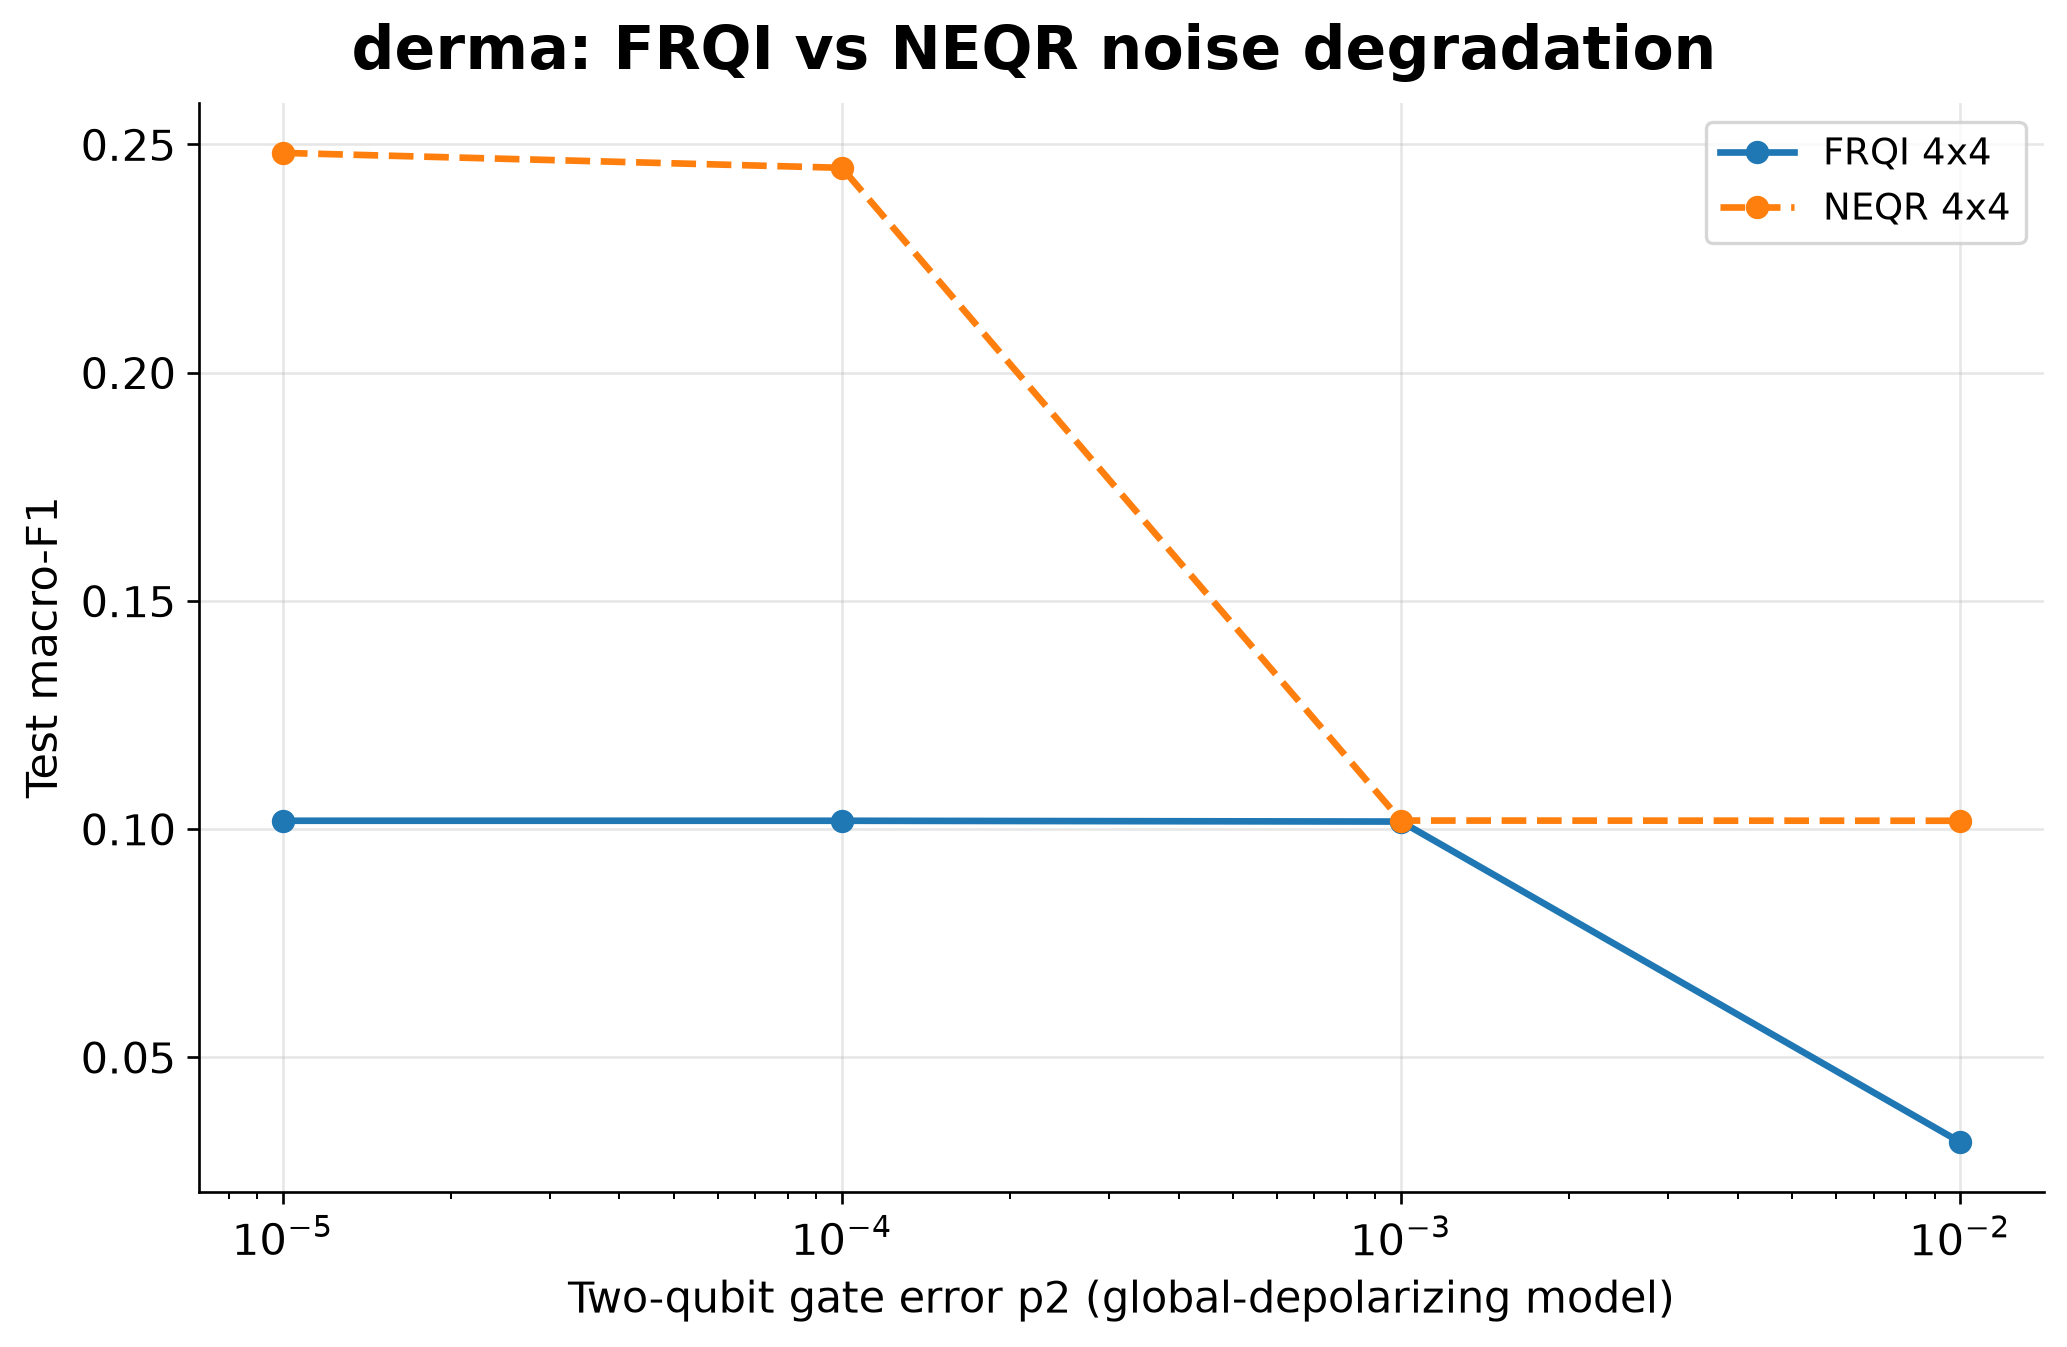

Saved blood_noise_degradation.png: 2584 x 1684 px at 300 dpi (+ PDF)


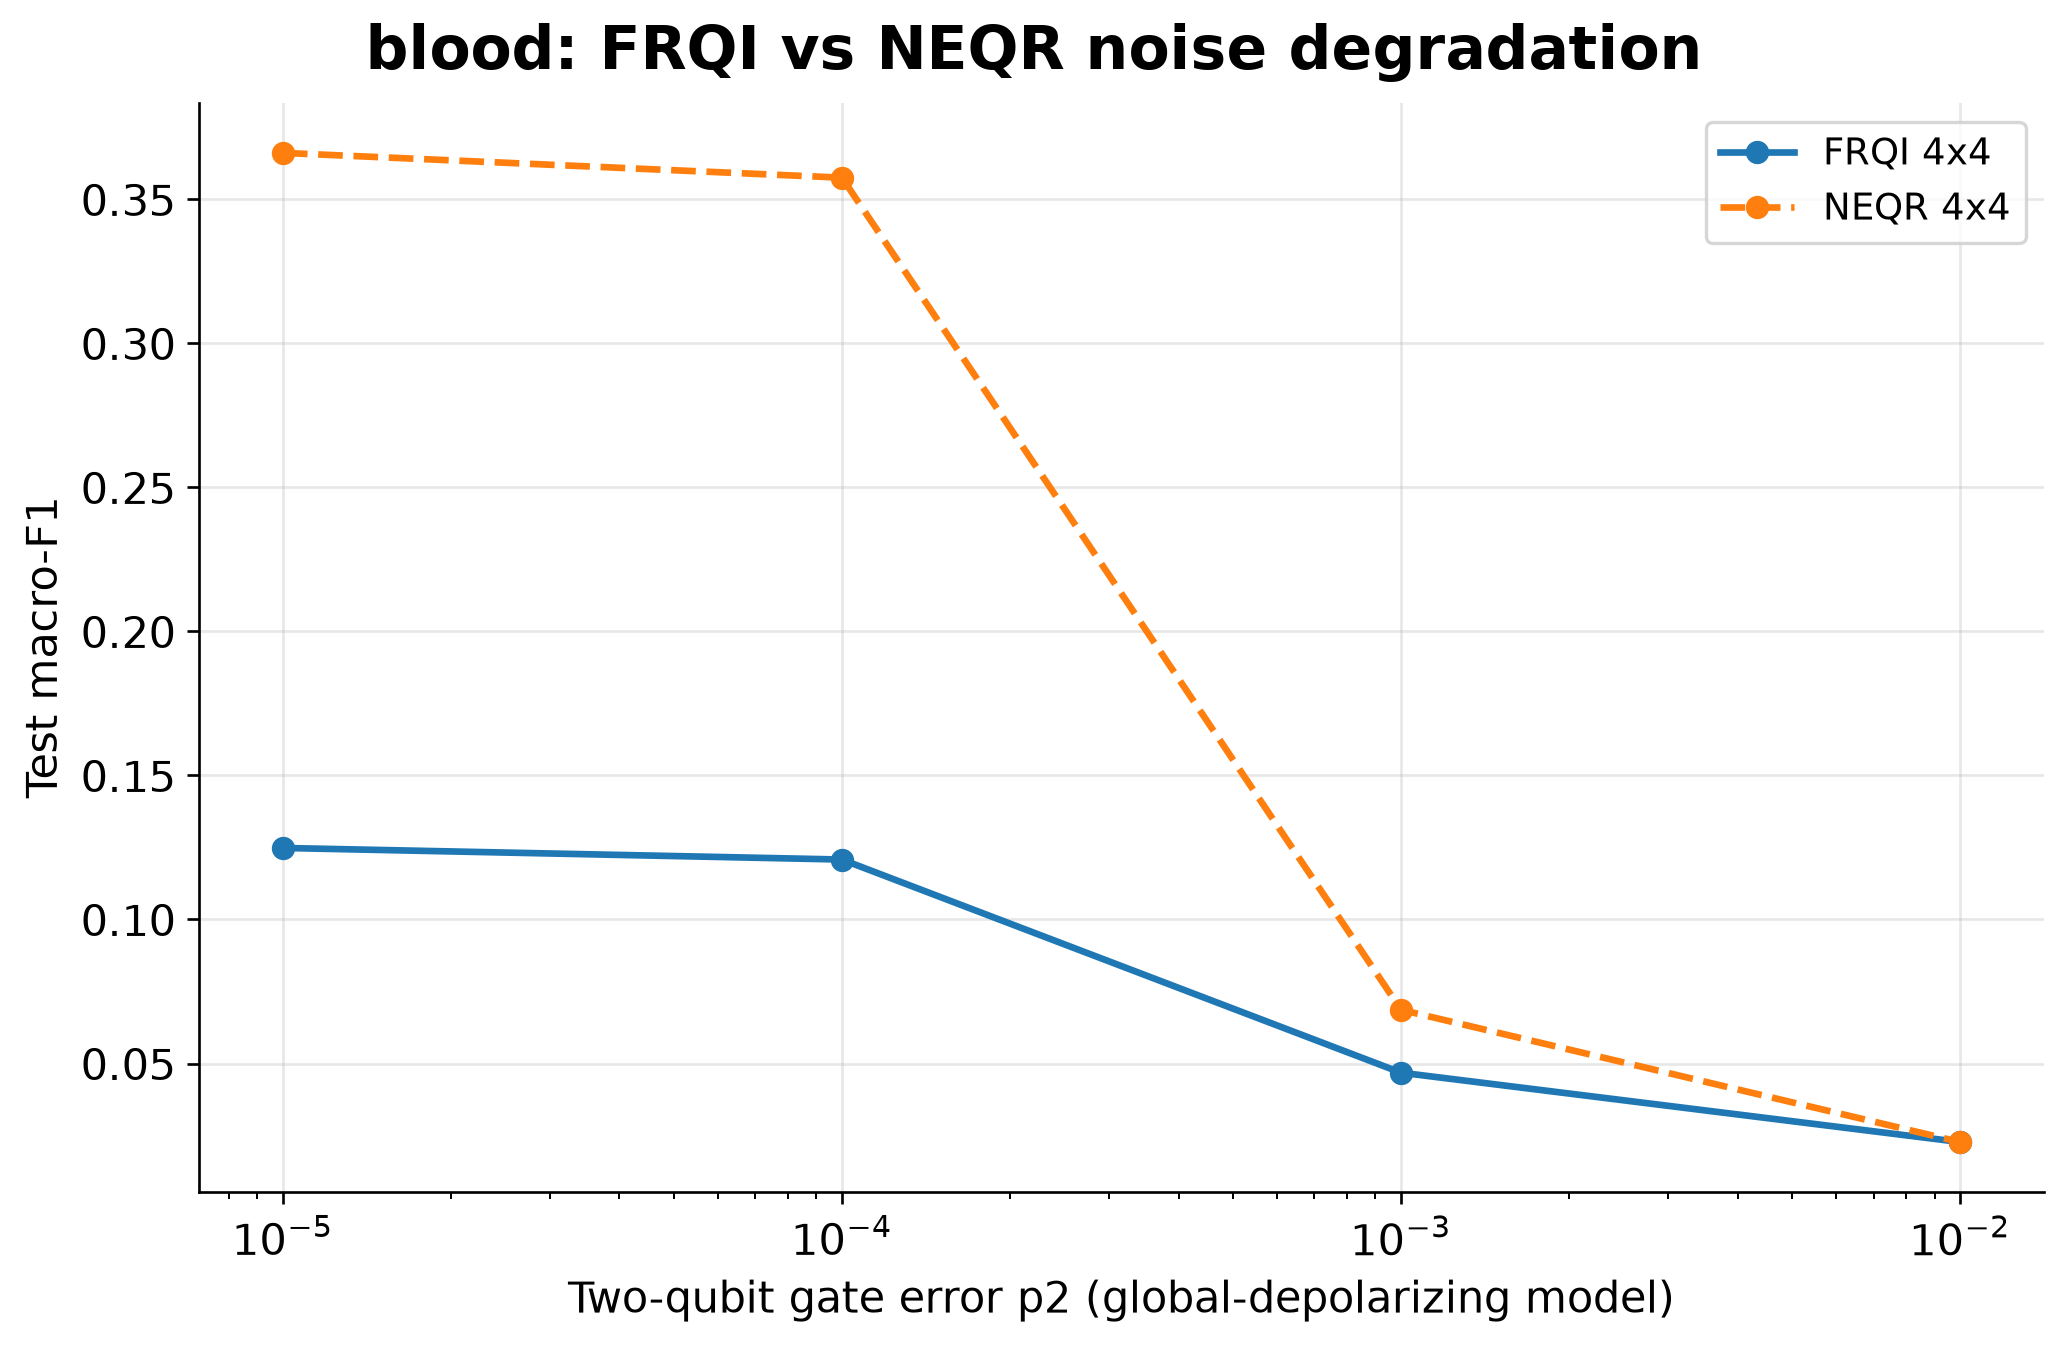


Noise analysis finished: 32 completed rows, 0 failed/skipped rows.
Raw results:  C:\Users\sripo\OneDrive\Desktop\Hybrid_QIP\results_quantum_smoke\noise_robustness.csv
Completed results:  C:\Users\sripo\OneDrive\Desktop\Hybrid_QIP\results_quantum_smoke\noise_robustness_completed.csv


In [67]:
import traceback
import zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ENC_GATES = {}

# ------------------------------------------------------------
# 1. Load measured encoder gate counts
# ------------------------------------------------------------
if circuit_rows and any(
    r.get("status") == "measured" for r in circuit_rows
):
    cdf = pd.DataFrame([
        r for r in circuit_rows
        if r.get("status") == "measured"
    ])

    required_gate_cols = {
        "image_size",
        "encoding",
        "compiled_cx",
        "compiled_total_gates",
    }

    missing = required_gate_cols - set(cdf.columns)

    if missing:
        print(
            "Cannot calculate encoder gate counts. "
            f"Missing columns: {sorted(missing)}"
        )
    else:
        for (res_, enc_), group in cdf.groupby(
            ["image_size", "encoding"]
        ):
            cx_values = pd.to_numeric(
                group["compiled_cx"], errors="coerce"
            )
            total_values = pd.to_numeric(
                group["compiled_total_gates"], errors="coerce"
            )

            valid = cx_values.notna() & total_values.notna()

            if not valid.any():
                continue

            mean_cx = float(cx_values[valid].mean())
            mean_1q = float(
                (total_values[valid] - cx_values[valid]).mean()
            )

            if mean_1q < 0:
                print(
                    f"Warning: negative estimated 1-qubit gate count "
                    f"for resolution={res_}, encoding={enc_}. "
                    "Check the gate-count schema."
                )
                continue

            ENC_GATES[(int(res_), enc_)] = (
                mean_cx,
                mean_1q,
            )

        print(
            "Measured encoder gate counts "
            "(mean CX, mean non-CX gates):",
            {
                k: tuple(round(v) for v in val)
                for k, val in ENC_GATES.items()
            },
        )
else:
    NOT_RUN.append({
        "item": "gate-noise (depolarizing) analysis",
        "reason": (
            "No measured Qiskit gate counts. Install compatible "
            "qiskit and qiskit-aer versions, then rerun the circuit "
            "measurement cell."
        ),
    })
    print(
        "No measured encoder gate counts. "
        "Depolarizing analysis will be skipped."
    )


# ------------------------------------------------------------
# 2. Metric compatibility helper
# ------------------------------------------------------------
def get_noise_metric_dict(
    y_true, y_pred, probabilities, class_labels
):
    """
    Support multiclass_metrics returning either:
      - a dictionary of metrics
      - (metrics_dictionary, additional_information)
    """
    result = multiclass_metrics(
        y_true,
        y_pred,
        probabilities,
        class_labels,
    )

    if isinstance(result, dict):
        return result

    if (
        isinstance(result, (tuple, list))
        and len(result) > 0
        and isinstance(result[0], dict)
    ):
        return result[0]

    raise TypeError(
        "Unexpected multiclass_metrics() return type: "
        f"{type(result).__name__}"
    )


# ------------------------------------------------------------
# 3. Run noise configurations
# ------------------------------------------------------------
NOISE_ROWS = []

for key, d in DATASETS_Q.items():

    print(f"\n{'=' * 65}")
    print(f"Noise robustness: {key}")
    print(f"{'=' * 65}")

    ids = np.asarray(d["class_ids"])
    raw = d["raw"]

    yte = raw["labels"][d["idx"]["test"]]

    src = (
        "pred_box"
        if d.get("pred_lookup")
        else "gt_box"
    )

    for res in VQC_CFG["res"]:

        print(f"\nResolution: {res}x{res}")

        try:
            Xte = roi_tensor(d, "test", src, res)
            channels = Xte.shape[1]
        except Exception as exc:
            traceback.print_exc()

            NOISE_ROWS.append({
                "dataset": key,
                "resolution": res,
                "roi_test_source": src,
                "status": (
                    f"failed: ROI preparation: "
                    f"{type(exc).__name__}: {exc}"
                ),
            })

            pd.DataFrame(NOISE_ROWS).to_csv(
                RESULTS_DIR / "noise_robustness.csv",
                index=False,
            )
            continue

        for enc in ("FRQI", "NEQR"):

            # Require a previously trained model checkpoint.
            model_key = (key, res, enc)

            if model_key not in VQC_MODELS:
                print(
                    f"Skipping {key}/{res}x{res}/{enc}: "
                    "trained model checkpoint not found."
                )

                NOISE_ROWS.append({
                    "dataset": key,
                    "resolution": res,
                    "encoding": enc,
                    "roi_test_source": src,
                    "status": "skipped: trained checkpoint unavailable",
                })

                pd.DataFrame(NOISE_ROWS).to_csv(
                    RESULTS_DIR / "noise_robustness.csv",
                    index=False,
                )
                continue

            try:
                model = QuantumClassifier(
                    enc,
                    res,
                    channels,
                    VQC_CFG["layers"],
                    len(ids),
                    0,
                ).to(DEVICE)

                model.load_state_dict(
                    VQC_MODELS[model_key]
                )
                model.eval()

            except Exception as exc:
                traceback.print_exc()

                NOISE_ROWS.append({
                    "dataset": key,
                    "resolution": res,
                    "encoding": enc,
                    "roi_test_source": src,
                    "status": (
                        f"failed: model loading: "
                        f"{type(exc).__name__}: {exc}"
                    ),
                })

                pd.DataFrame(NOISE_ROWS).to_csv(
                    RESULTS_DIR / "noise_robustness.csv",
                    index=False,
                )
                continue

            # ------------------------------------------------
            # Gate-count estimates
            # ------------------------------------------------
            n_cx_enc, n_1q_enc = ENC_GATES.get(
                (res, enc),
                (np.nan, np.nan),
            )

            n_ring = len(model.qmap.ring)
            L = VQC_CFG["layers"]

            n_cx = (
                n_cx_enc + L * n_ring
                if np.isfinite(n_cx_enc)
                else np.nan
            )

            n_1q = (
                n_1q_enc
                + L * (model.n_qubits + 2 * n_ring)
                if np.isfinite(n_1q_enc)
                else np.nan
            )

            # ------------------------------------------------
            # Noise settings
            # ------------------------------------------------
            settings = [
                ("ideal_exact", 0.0, 0.0, None, 0.0),
                ("shots_only", 0.0, 0.0, NOISE_SHOTS, 0.0),
            ]

            settings += [
                ("readout", e, 0.0, NOISE_SHOTS, e)
                for e in READOUT_GRID
                if e > 0
            ]

            # Do not invent gate counts when measurement data
            # is missing. Skip only the gate-based noise cases.
            if np.isfinite(n_cx) and np.isfinite(n_1q):
                settings += [
                    (
                        "depolarizing",
                        0.0,
                        depolarizing_lambda(
                            n_cx, n_1q, p2
                        ),
                        NOISE_SHOTS,
                        p2,
                    )
                    for p2 in P2_GRID
                    if p2 > 0
                ]
            else:
                print(
                    f"Depolarizing cases skipped for {enc}, "
                    f"{res}x{res}: gate counts unavailable."
                )

            # ------------------------------------------------
            # Evaluate every configuration
            # ------------------------------------------------
            for name, e, lam, shots, level in settings:

                print(
                    f"Evaluating {key}/{res}x{res}/{enc}: "
                    f"{name}, level={level}"
                )

                try:
                    seed_text = (
                        f"{key}{res}{enc}{name}{level}"
                    )

                    rng_seed = [
                        int(SEED),
                        int(zlib.crc32(seed_text.encode())),
                    ]

                    p = noisy_probabilities(
                        model,
                        Xte,
                        e,
                        lam,
                        shots,
                        np.random.default_rng(rng_seed),
                    )

                    p = np.asarray(p)

                    # Validate probability shape before computing
                    # classification metrics.
                    if p.ndim != 2:
                        raise ValueError(
                            f"Expected 2D probability array; "
                            f"received shape {p.shape}"
                        )

                    if p.shape[0] != len(yte):
                        raise ValueError(
                            f"Prediction count {p.shape[0]} "
                            f"does not match test labels {len(yte)}"
                        )

                    if p.shape[1] != len(ids):
                        raise ValueError(
                            f"Probability columns {p.shape[1]} "
                            f"do not match class count {len(ids)}"
                        )

                    if not np.isfinite(p).all():
                        raise ValueError(
                            "Predictions contain NaN or infinity."
                        )

                    pred = ids[p.argmax(axis=1)]

                    # FIX: no unconditional [0] indexing.
                    m = get_noise_metric_dict(
                        yte,
                        pred,
                        p,
                        list(ids),
                    )

                    row = {
                        "dataset": key,
                        "resolution": res,
                        "encoding": enc,
                        "roi_test_source": src,
                        "noise": name,
                        "level": level,
                        "shots": shots,
                        "lambda_total": lam,
                        "encoder_cx": n_cx_enc,
                        "encoder_1q_estimate": n_1q_enc,
                        "total_cx": n_cx,
                        "total_1q": n_1q,
                        "qubits": model.n_qubits,
                        "status": "completed",
                        **m,
                    }

                    NOISE_ROWS.append(row)

                    print(
                        f"Completed: {name}, "
                        f"macro-F1={m.get('macro_f1', np.nan)}"
                    )

                except Exception as exc:
                    traceback.print_exc()

                    NOISE_ROWS.append({
                        "dataset": key,
                        "resolution": res,
                        "encoding": enc,
                        "roi_test_source": src,
                        "noise": name,
                        "level": level,
                        "shots": shots,
                        "lambda_total": lam,
                        "encoder_cx": n_cx_enc,
                        "encoder_1q_estimate": n_1q_enc,
                        "total_cx": n_cx,
                        "total_1q": n_1q,
                        "qubits": getattr(
                            model, "n_qubits", np.nan
                        ),
                        "status": (
                            f"failed: {type(exc).__name__}: {exc}"
                        ),
                    })

                finally:
                    # Persist progress after every configuration.
                    pd.DataFrame(NOISE_ROWS).to_csv(
                        RESULTS_DIR / "noise_robustness.csv",
                        index=False,
                    )


# ------------------------------------------------------------
# 4. Build completed-run summary safely
# ------------------------------------------------------------
noise_df = pd.DataFrame(NOISE_ROWS)

if noise_df.empty:
    print("\nNo noise-analysis rows were generated.")

else:
    noise_df.to_csv(
        RESULTS_DIR / "noise_robustness.csv",
        index=False,
    )

    if "status" in noise_df.columns:
        noise_ok = noise_df[
            noise_df["status"].eq("completed")
        ].copy()
    else:
        noise_ok = noise_df.copy()

    if noise_ok.empty:
        print("\nNo noise configurations completed.")
        print(
            noise_df[
                [
                    c for c in [
                        "dataset", "resolution", "encoding",
                        "noise", "status"
                    ]
                    if c in noise_df.columns
                ]
            ].to_string(index=False)
        )

    else:
        # Compare each noisy run against the matching ideal run.
        if "macro_f1" in noise_ok.columns:
            ideal_rows = noise_ok[
                noise_ok["noise"].eq("ideal_exact")
            ]

            ideal = ideal_rows.set_index(
                ["dataset", "resolution", "encoding"]
            )["macro_f1"]

            noise_ok["macro_f1_drop_vs_ideal"] = [
                (
                    ideal.get(
                        (r.dataset, r.resolution, r.encoding),
                        np.nan,
                    ) - r.macro_f1
                )
                if pd.notna(r.macro_f1)
                else np.nan
                for r in noise_ok.itertuples()
            ]

        display_cols = [
            c for c in [
                "dataset", "resolution", "encoding",
                "noise", "level", "lambda_total",
                "total_cx", "macro_f1",
                "macro_f1_drop_vs_ideal"
            ]
            if c in noise_ok.columns
        ]

        display(noise_ok[display_cols].round(4))

        noise_ok.to_csv(
            RESULTS_DIR / "noise_robustness_completed.csv",
            index=False,
        )

        # ----------------------------------------------------
        # 5. Plot depolarizing degradation only if available
        # ----------------------------------------------------
        if (
            "noise" in noise_ok.columns
            and "macro_f1" in noise_ok.columns
            and "level" in noise_ok.columns
        ):
            for dataset_name in noise_ok["dataset"].dropna().unique():

                sub = noise_ok[
                    (noise_ok["dataset"] == dataset_name)
                    & (noise_ok["noise"] == "depolarizing")
                ].copy()

                if sub.empty:
                    continue

                fig, ax = plt.subplots(
                    figsize=(8.5, 5.5),
                    constrained_layout=True,
                )

                for (encoding, resolution), group in sub.groupby(
                    ["encoding", "resolution"]
                ):
                    group = group.sort_values("level")

                    group = group[
                        (group["level"] > 0)
                        & group["macro_f1"].notna()
                    ]

                    if group.empty:
                        continue

                    ax.plot(
                        group["level"],
                        group["macro_f1"],
                        marker="o",
                        linewidth=2,
                        linestyle=(
                            "-" if encoding == "FRQI" else "--"
                        ),
                        label=f"{encoding} {resolution}x{resolution}",
                    )

                if ax.lines:
                    ax.set_xscale("log")
                    ax.set_xlabel(
                        "Two-qubit gate error p2 "
                        "(global-depolarizing model)"
                    )
                    ax.set_ylabel("Test macro-F1")
                    ax.grid(alpha=0.3)
                    ax.legend()
                    fig.suptitle(
                        f"{dataset_name}: FRQI vs NEQR "
                        "noise degradation"
                    )

                    save_fig(
                        fig,
                        f"{dataset_name}_noise_degradation",
                    )
                    plt.show()
                else:
                    plt.close(fig)

    failed_count = (
        int((noise_df["status"] != "completed").sum())
        if "status" in noise_df.columns
        else 0
    )

    completed_count = (
        int((noise_df["status"] == "completed").sum())
        if "status" in noise_df.columns
        else len(noise_df)
    )

    print(
        f"\nNoise analysis finished: "
        f"{completed_count} completed rows, "
        f"{failed_count} failed/skipped rows."
    )

    print(
        "Raw results: ",
        RESULTS_DIR / "noise_robustness.csv",
    )

    print(
        "Completed results: ",
        RESULTS_DIR / "noise_robustness_completed.csv",
    )


In [68]:
AER_NOISE_MAX_QUBITS, AER_NOISE_IMAGES, AER_NOISE_P2, AER_NOISE_SHOTS = 12, 2, 1e-3, 2048       # NEQR 4x4 has 12 qubits: slow (minutes per image); lower the numbers to shorten
AER_NOISE_ROWS = []
if QISKIT_OK and AER_OK:
    from qiskit_aer.noise import NoiseModel, depolarizing_error
    first_d = next(iter(DATASETS_Q.values())); rois, _ = roi_stack(first_d, "test", "gt_box", 4)
    nm = NoiseModel(); nm.add_all_qubit_quantum_error(depolarizing_error(P1_OVER_P2 * AER_NOISE_P2, 1), ["u"]); nm.add_all_qubit_quantum_error(depolarizing_error(AER_NOISE_P2, 2), ["cx"])
    zexp = lambda P, n: np.array([(P * (1 - 2 * ((np.arange(2 ** n) >> q) & 1))).sum() for q in range(n)])
    for enc in ("FRQI", "NEQR"):
        n = n_qubits_for(enc, 4)
        if n > AER_NOISE_MAX_QUBITS: continue
        for k in range(AER_NOISE_IMAGES):
            try:
                t0 = time.perf_counter(); qc, _ = build_circuit(rois[k], enc); comp = transpile(qc, basis_gates=["u", "cx"], optimization_level=1, seed_transpiler=SEED); ops = comp.count_ops()
                n_cx, n_1q = int(ops.get("cx", 0)), int(sum(ops.values()) - ops.get("cx", 0)); lam = depolarizing_lambda(n_cx, n_1q, AER_NOISE_P2)
                comp.measure_all(); sim = AerSimulator(noise_model=nm, method="density_matrix")
                counts = sim.run(comp, shots=AER_NOISE_SHOTS, seed_simulator=SEED).result().get_counts(); emp = np.zeros(2 ** n)
                for bits, c in counts.items(): emp[int(bits.replace(" ", ""), 2)] += c
                emp /= AER_NOISE_SHOTS; exact = born_probabilities(rois[k], enc)
                z_aer, z_model, z_ideal = zexp(emp, n), (1 - lam) * zexp(exact, n), zexp(exact, n)
                AER_NOISE_ROWS.append({"encoding": enc, "image": k, "qubits": n, "cx": n_cx, "p2": AER_NOISE_P2, "lambda_model": lam, "mean_abs_Z_ideal_minus_aer": float(np.abs(z_ideal - z_aer).mean()),
                                       "mean_abs_Z_model_minus_aer": float(np.abs(z_model - z_aer).mean()), "seconds": time.perf_counter() - t0})
            except Exception as exc:
                AER_NOISE_ROWS.append({"encoding": enc, "image": k, "status": f"failed: {type(exc).__name__}: {exc}"})
    aer_noise_df = pd.DataFrame(AER_NOISE_ROWS); display(aer_noise_df.round(4)); aer_noise_df.to_csv(RESULTS_DIR / "aer_noise_crosscheck.csv", index=False)
    print("Reading: if |model - aer| is clearly smaller than |ideal - aer|, the depolarizing model captures the dominant effect; if not, say so in the paper and treat the gate-noise curves as an upper bound on damage.")
else:
    NOT_RUN.append({"item": "Aer noisy cross-check", "reason": "qiskit / qiskit-aer unavailable"}); print("Aer cross-check NOT RUN")

,encoding,image,qubits,cx,p2,lambda_model,mean_abs_Z_ideal_minus_aer,mean_abs_Z_model_minus_aer,seconds
0,FRQI,0,5,1152,0.001,0.7221,0.0759,0.0281,0.2076
1,FRQI,1,5,1152,0.001,0.7221,0.0254,0.0193,0.1701
2,NEQR,0,12,1296,0.001,0.7675,0.1762,0.1189,92.5841
3,NEQR,1,12,1290,0.001,0.7647,0.0564,0.1119,78.4064


Reading: if |model - aer| is clearly smaller than |ideal - aer|, the depolarizing model captures the dominant effect; if not, say so in the paper and treat the gate-noise curves as an upper bound on damage.


Saved derma_main_comparison.png: 5134 x 1984 px at 300 dpi (+ PDF)


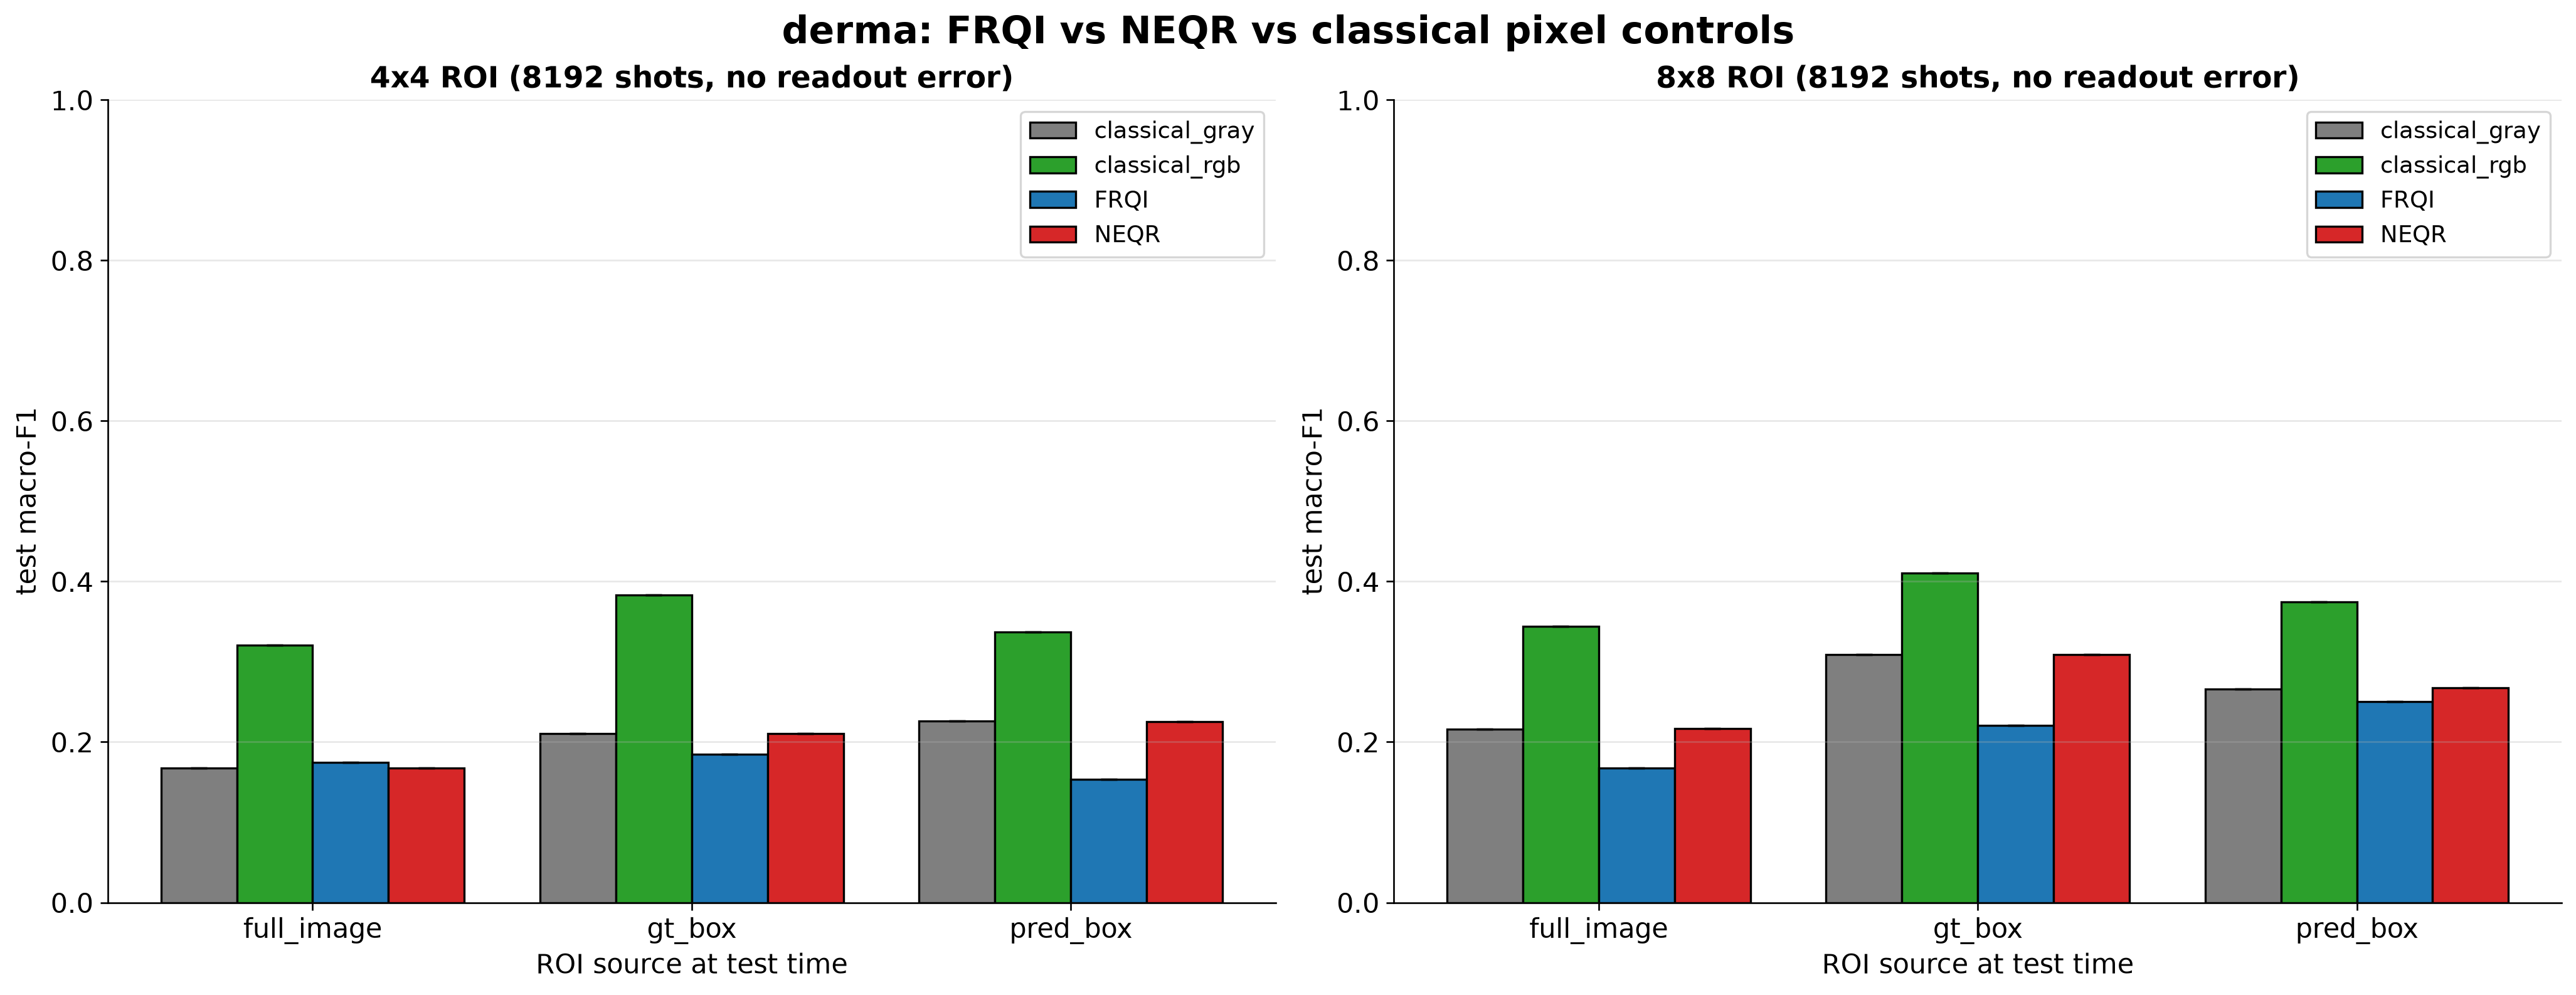

Saved blood_main_comparison.png: 5134 x 1984 px at 300 dpi (+ PDF)


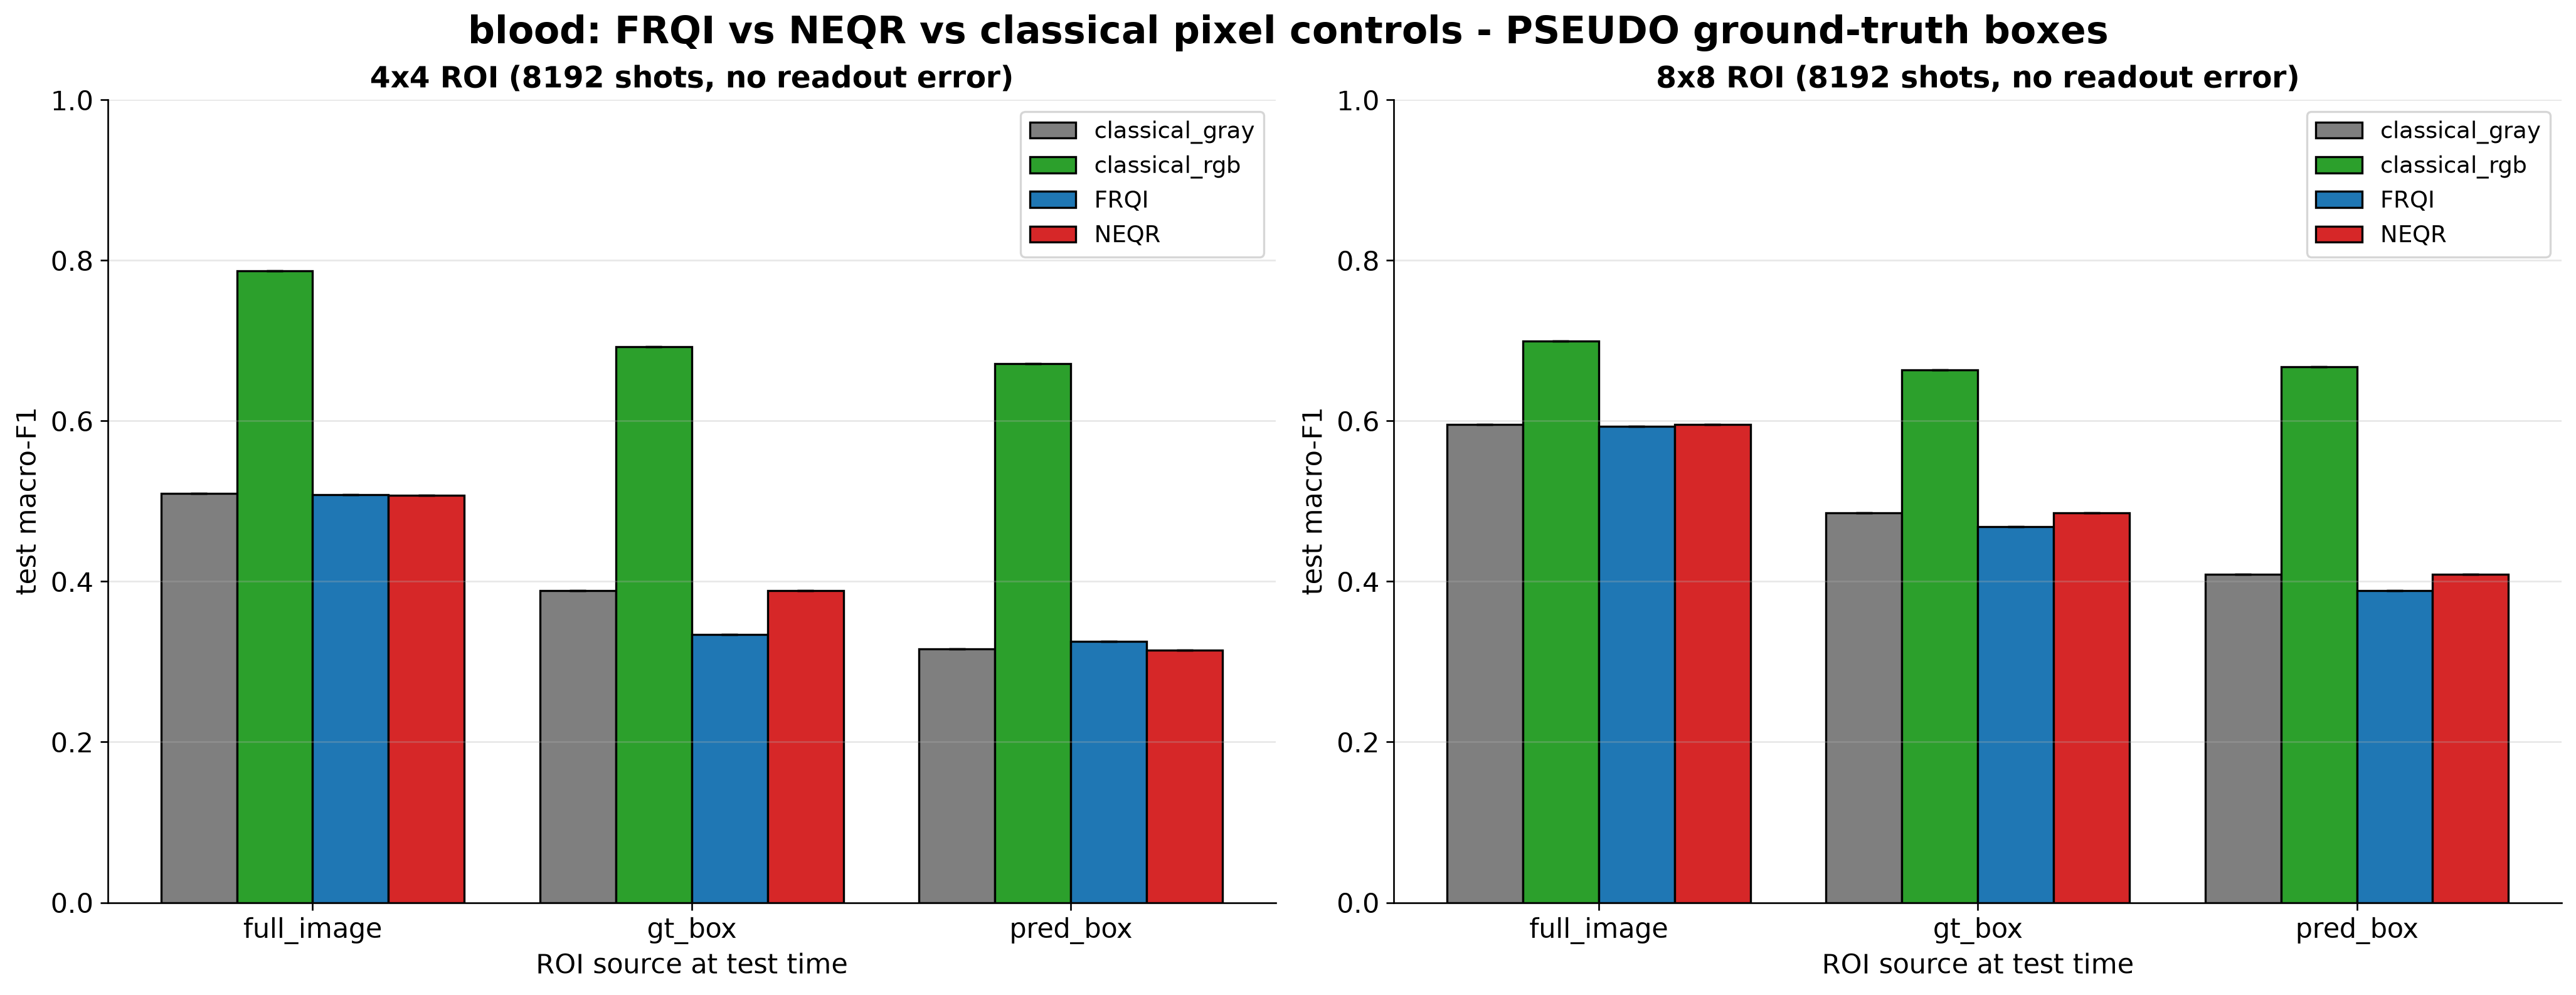

In [69]:
colours = {"classical_gray": "tab:gray", "classical_rgb": "tab:green", "FRQI": "tab:blue", "NEQR": "tab:red"}
for key in DATASETS_Q:
    fig, axes = plt.subplots(1, len(RES_LIST), figsize=(8.5 * len(RES_LIST), 6.5), constrained_layout=True, squeeze=False)
    for ax, res in zip(axes[0], RES_LIST):
        series = ["classical_gray", "classical_rgb", "FRQI", "NEQR"]; width = 0.8 / len(series)
        for k, name in enumerate(series):
            fam = "pixels" if name.startswith("classical") else "decoded"
            means, stds = [], []
            for src in SOURCES:
                sel = main_summary[(main_summary["dataset"] == key) & (main_summary["resolution"] == res) & (main_summary["roi_test_source"] == src) &
                                   (main_summary["encoding"] == name) & (main_summary["feature_family"] == fam) & (main_summary["classifier"] == "logreg")]
                means.append(float(sel["macro_f1_mean"].iloc[0]) if len(sel) else np.nan); stds.append(float(sel["macro_f1_std"].fillna(0).iloc[0]) if len(sel) else 0.0)
            ax.bar(np.arange(len(SOURCES)) + (k - (len(series) - 1) / 2) * width, means, width, yerr=stds, capsize=4, label=name, color=colours[name], edgecolor="black")
        ax.set_xticks(range(len(SOURCES))); ax.set_xticklabels(SOURCES); ax.set_ylim(0, 1); ax.set_ylabel("test macro-F1"); ax.set_xlabel("ROI source at test time")
        ax.set_title(f"{res}x{res} ROI ({MAIN_SHOTS} shots, no readout error)"); ax.grid(axis="y", alpha=0.3); ax.legend(loc="upper right")
    fig.suptitle(f"{key}: FRQI vs NEQR vs classical pixel controls" + (" - PSEUDO ground-truth boxes" if key == "blood" else ""))
    save_fig(fig, f"{key}_main_comparison"); plt.show()

Saved derma_shot_readout_sweep.png: 5134 x 1984 px at 300 dpi (+ PDF)


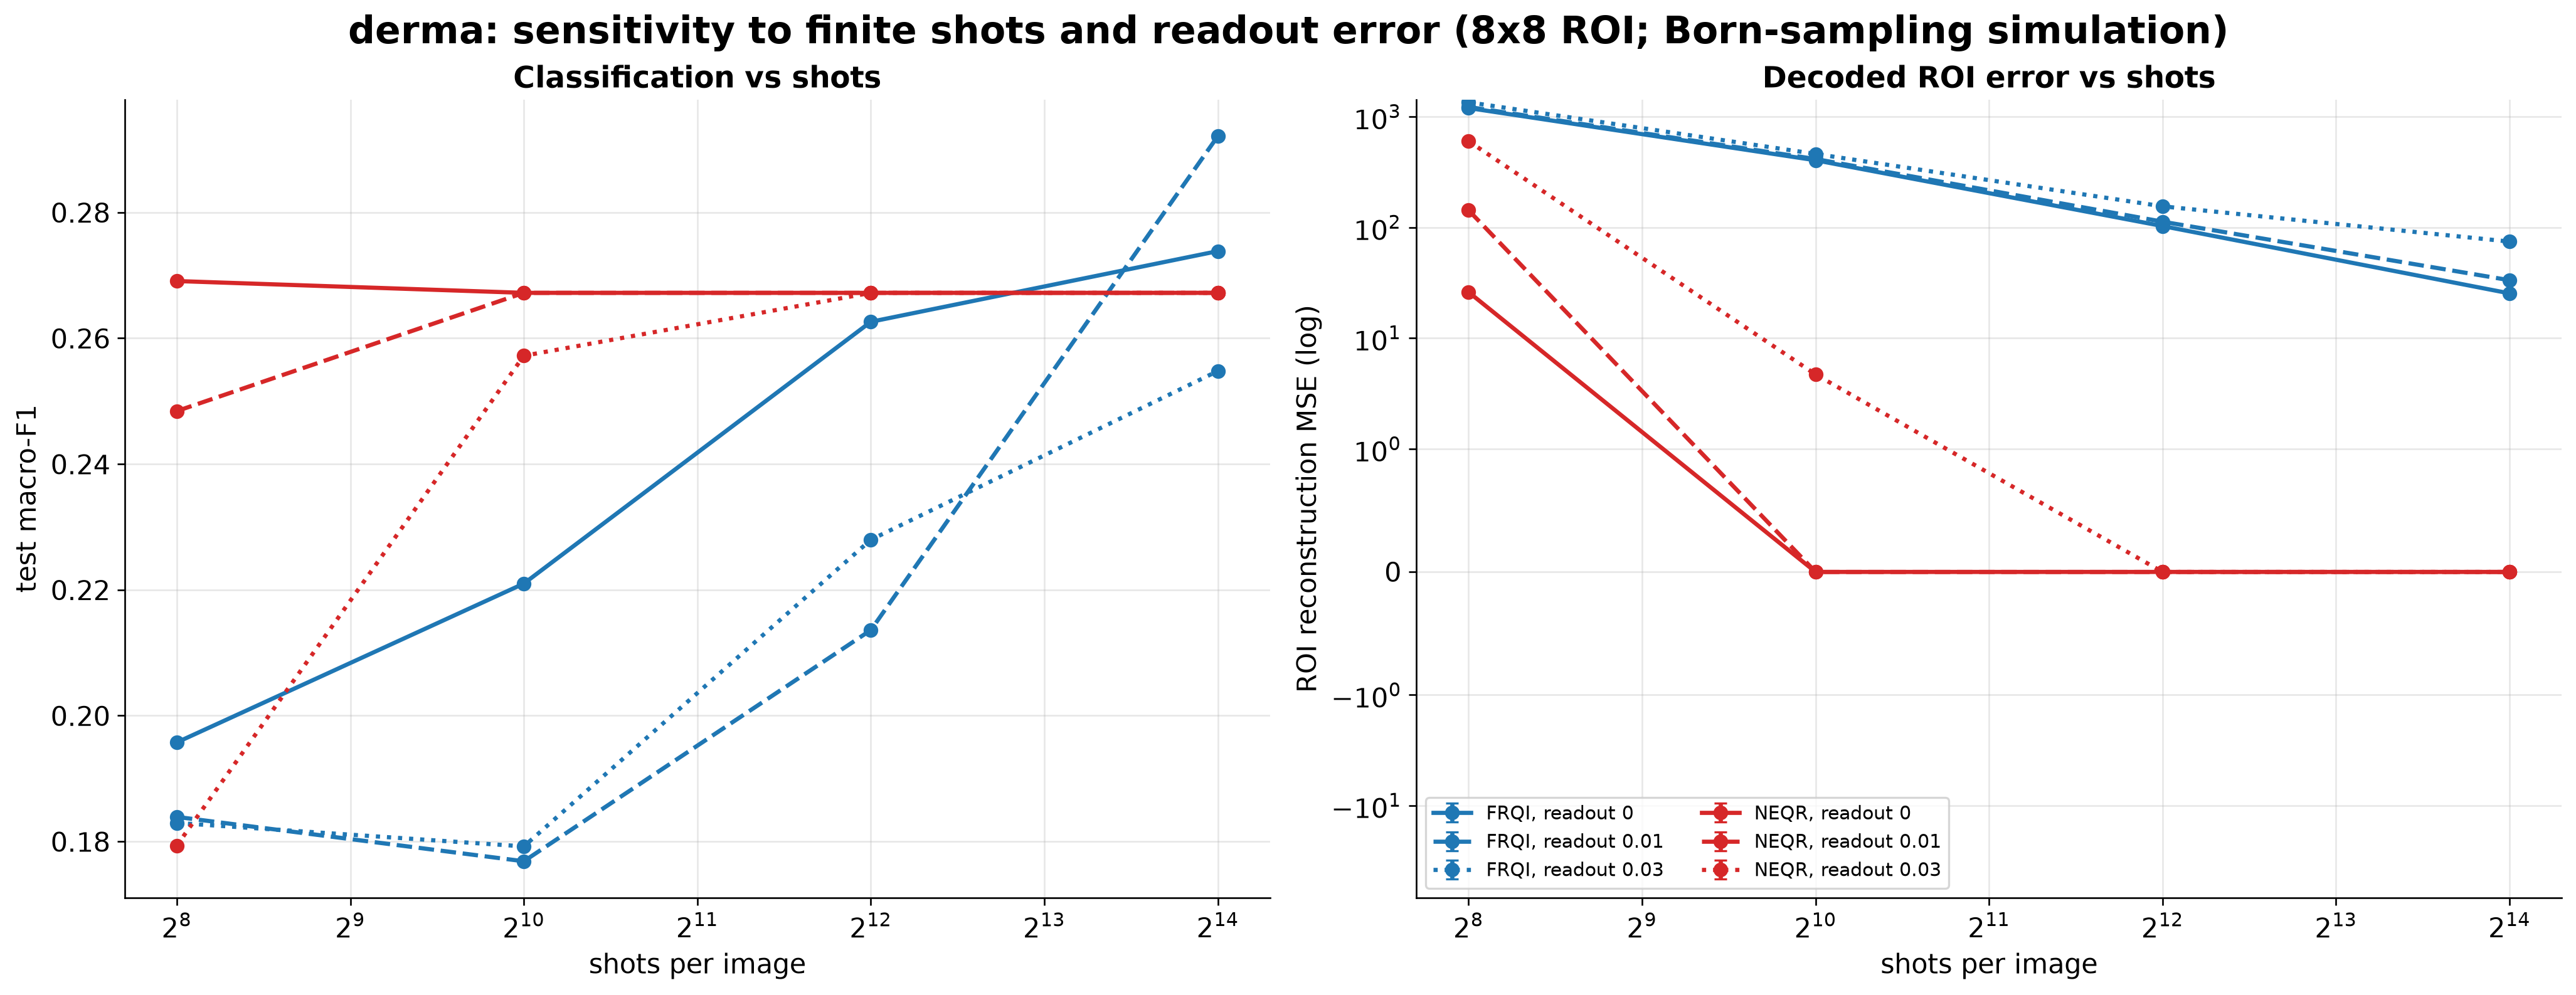

Saved blood_shot_readout_sweep.png: 5134 x 1984 px at 300 dpi (+ PDF)


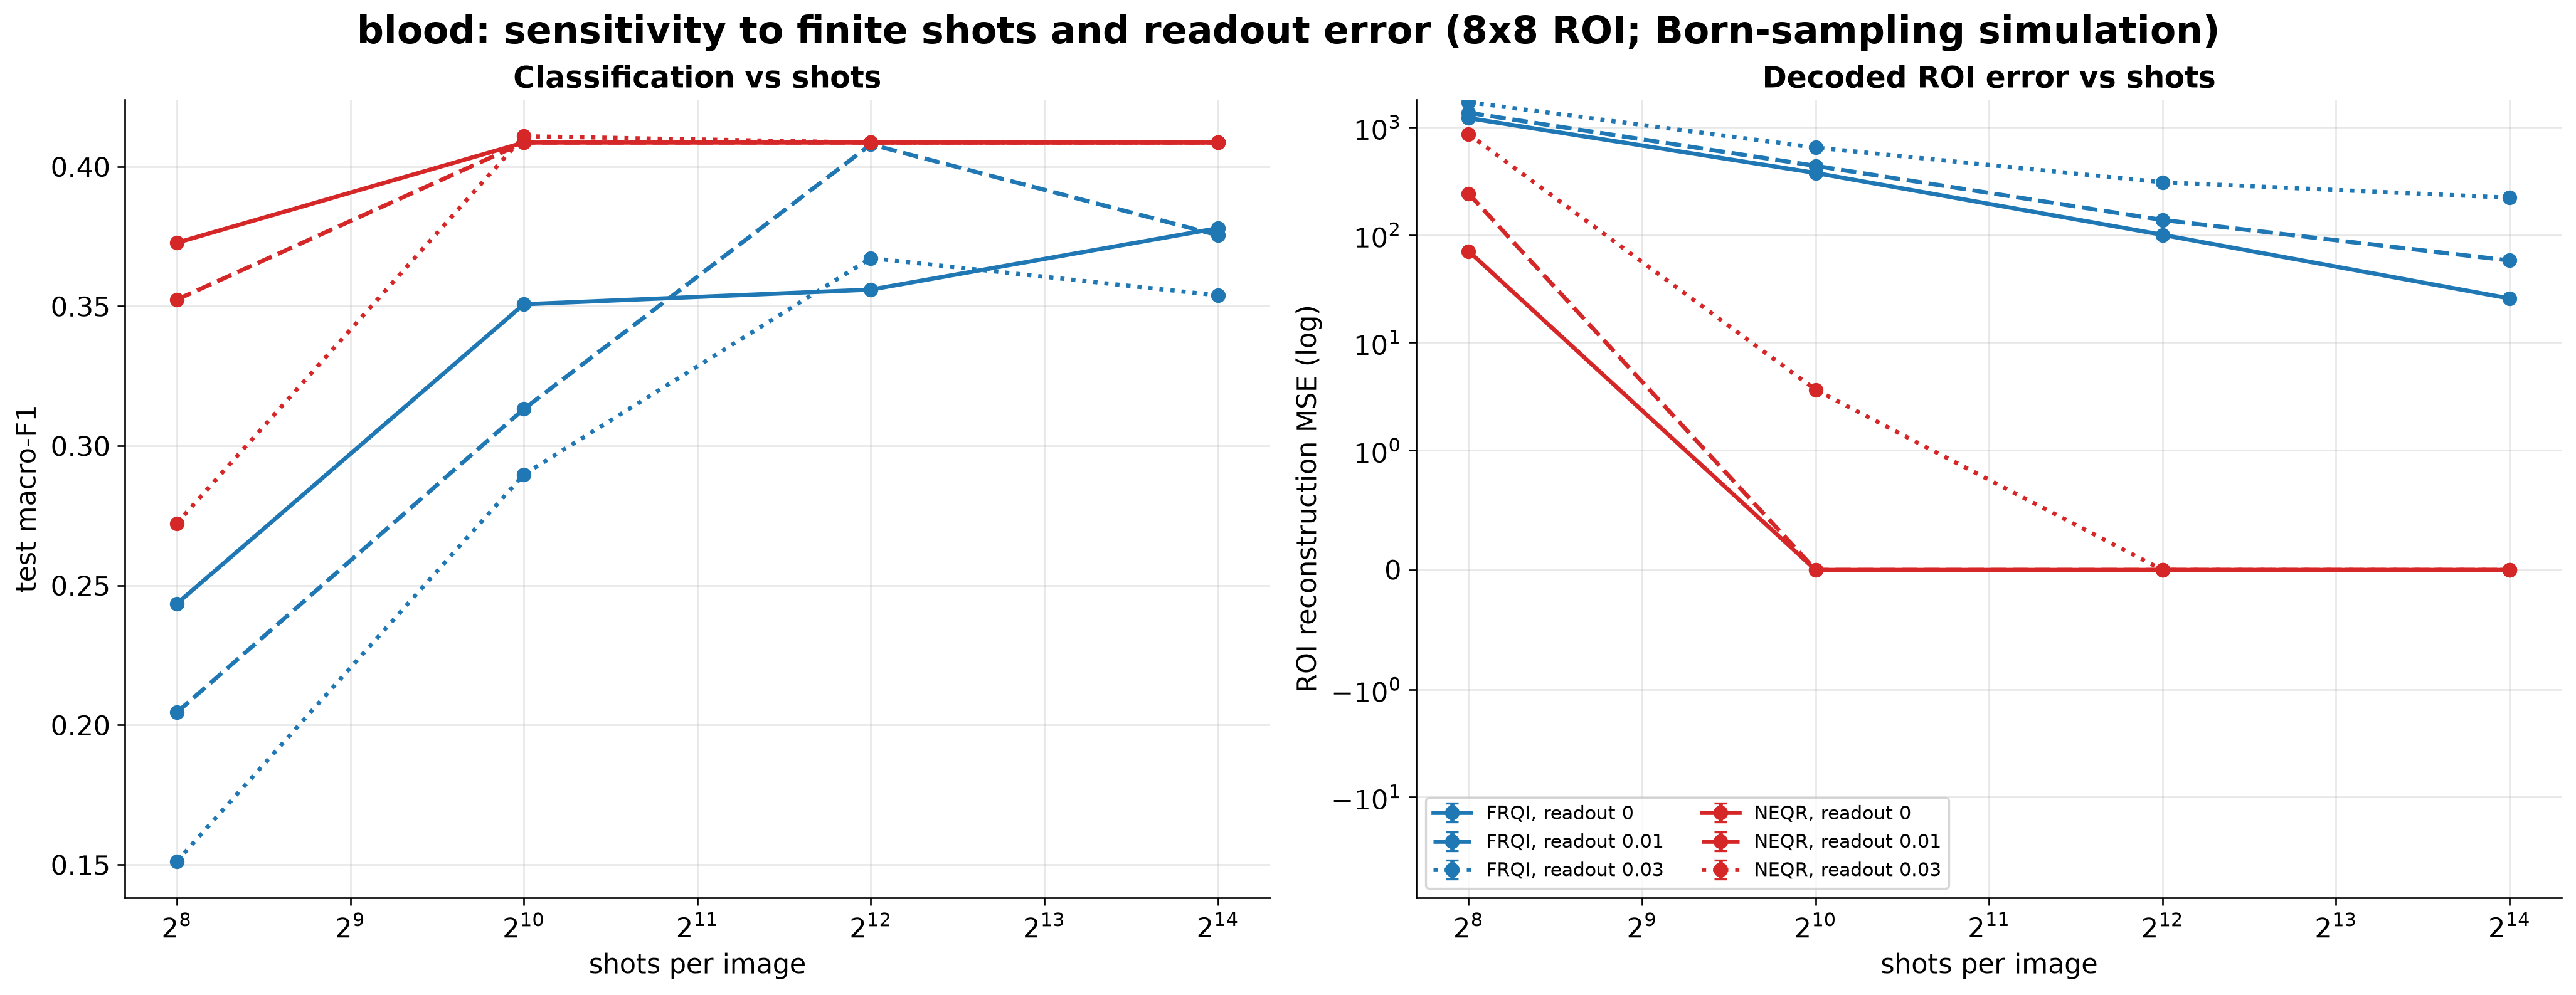

In [70]:
for key in DATASETS_Q:
    sub = sweep_summary[sweep_summary["dataset"] == key]
    fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), constrained_layout=True)
    for enc, colour in (("FRQI", "tab:blue"), ("NEQR", "tab:red")):
        for readout, ls in zip(READOUT_SWEEP, ["-", "--", ":"] + ["-."] * 5):
            s = sub[(sub["encoding"] == enc) & (sub["readout_error"] == readout)].sort_values("shots")
            axes[0].errorbar(s["shots"], s["macro_f1_mean"], yerr=s["macro_f1_std"].fillna(0), color=colour, linestyle=ls, marker="o", capsize=3, linewidth=2, label=f"{enc}, readout {readout:g}")
            axes[1].errorbar(s["shots"], s["recon_mse_test_mean"], yerr=s["recon_mse_test_std"].fillna(0), color=colour, linestyle=ls, marker="o", capsize=3, linewidth=2, label=f"{enc}, readout {readout:g}")
    for ax in axes:
        ax.set_xscale("log", base=2); ax.set_xlabel("shots per image"); ax.grid(alpha=0.3)
    axes[0].set_ylabel("test macro-F1"); axes[0].set_title("Classification vs shots"); axes[1].set_ylabel("ROI reconstruction MSE (log)"); axes[1].set_yscale("symlog", linthresh=1.0); axes[1].set_title("Decoded ROI error vs shots")
    axes[1].legend(fontsize=9, ncol=2)
    fig.suptitle(f"{key}: sensitivity to finite shots and readout error ({sweep_res}x{sweep_res} ROI; Born-sampling simulation)"); save_fig(fig, f"{key}_shot_readout_sweep"); plt.show()

Saved derma_roi_encoding_examples.png: 5686 x 4714 px at 300 dpi (+ PDF)


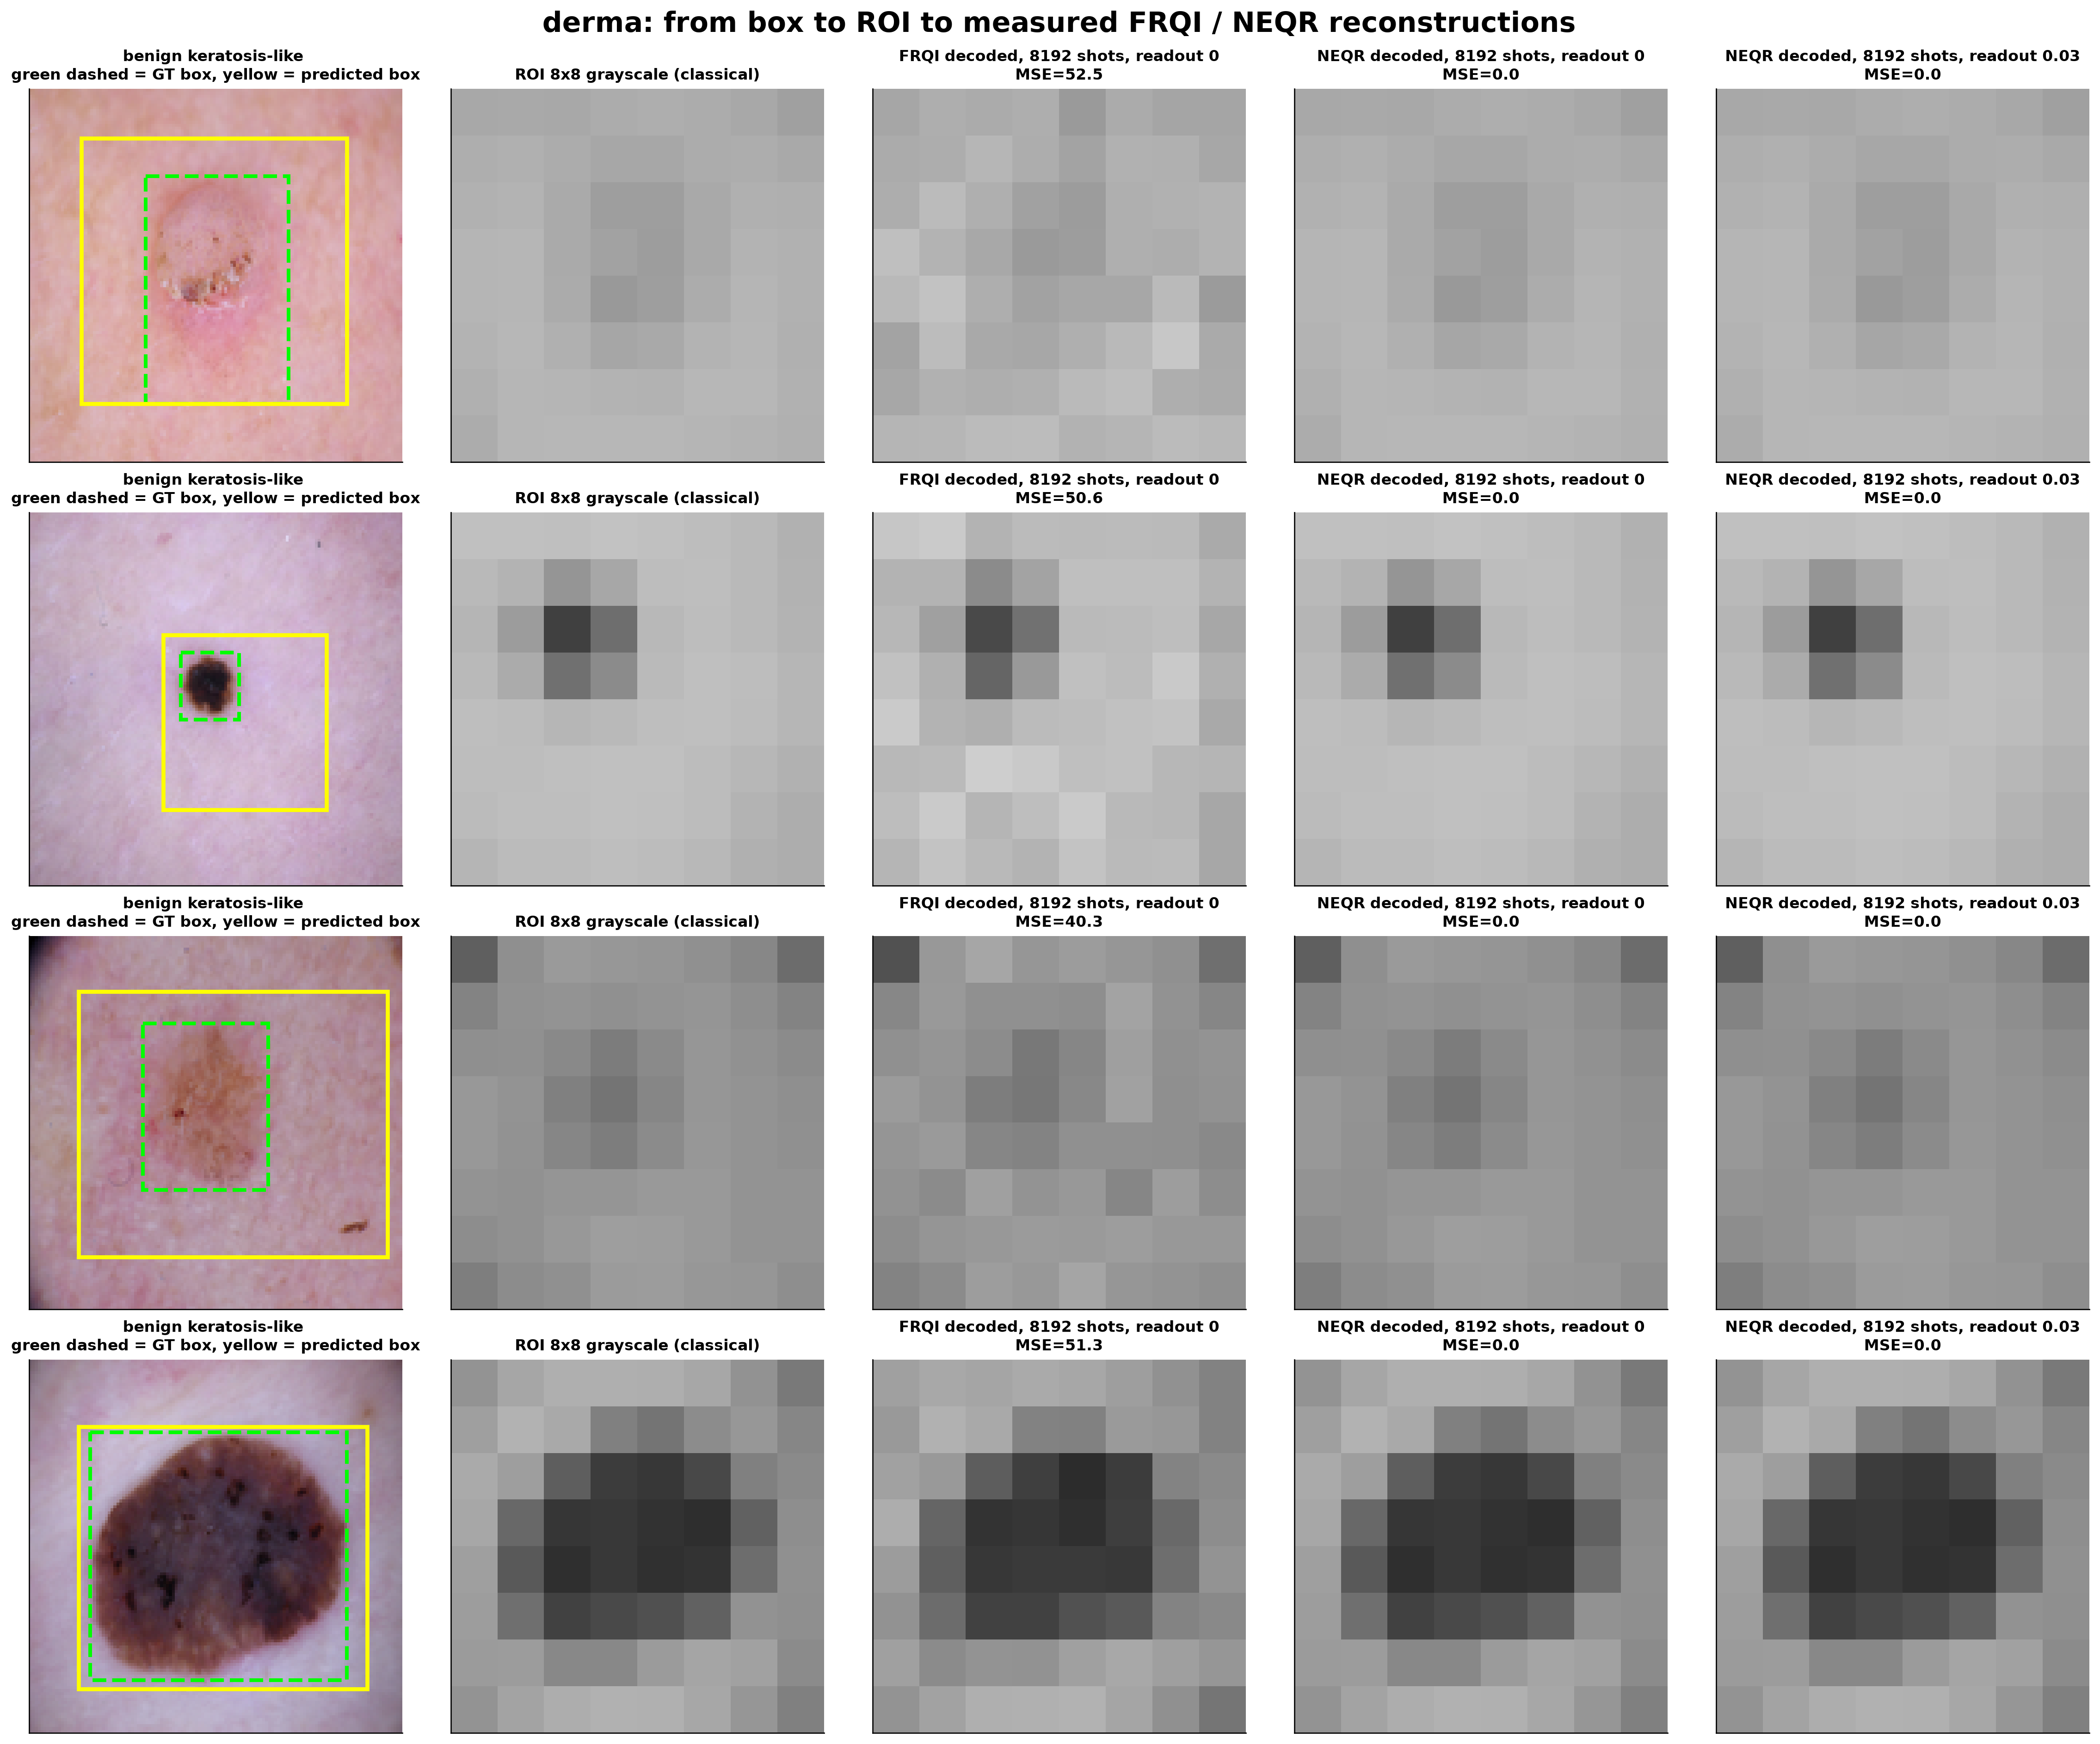

Saved blood_roi_encoding_examples.png: 5686 x 4714 px at 300 dpi (+ PDF)


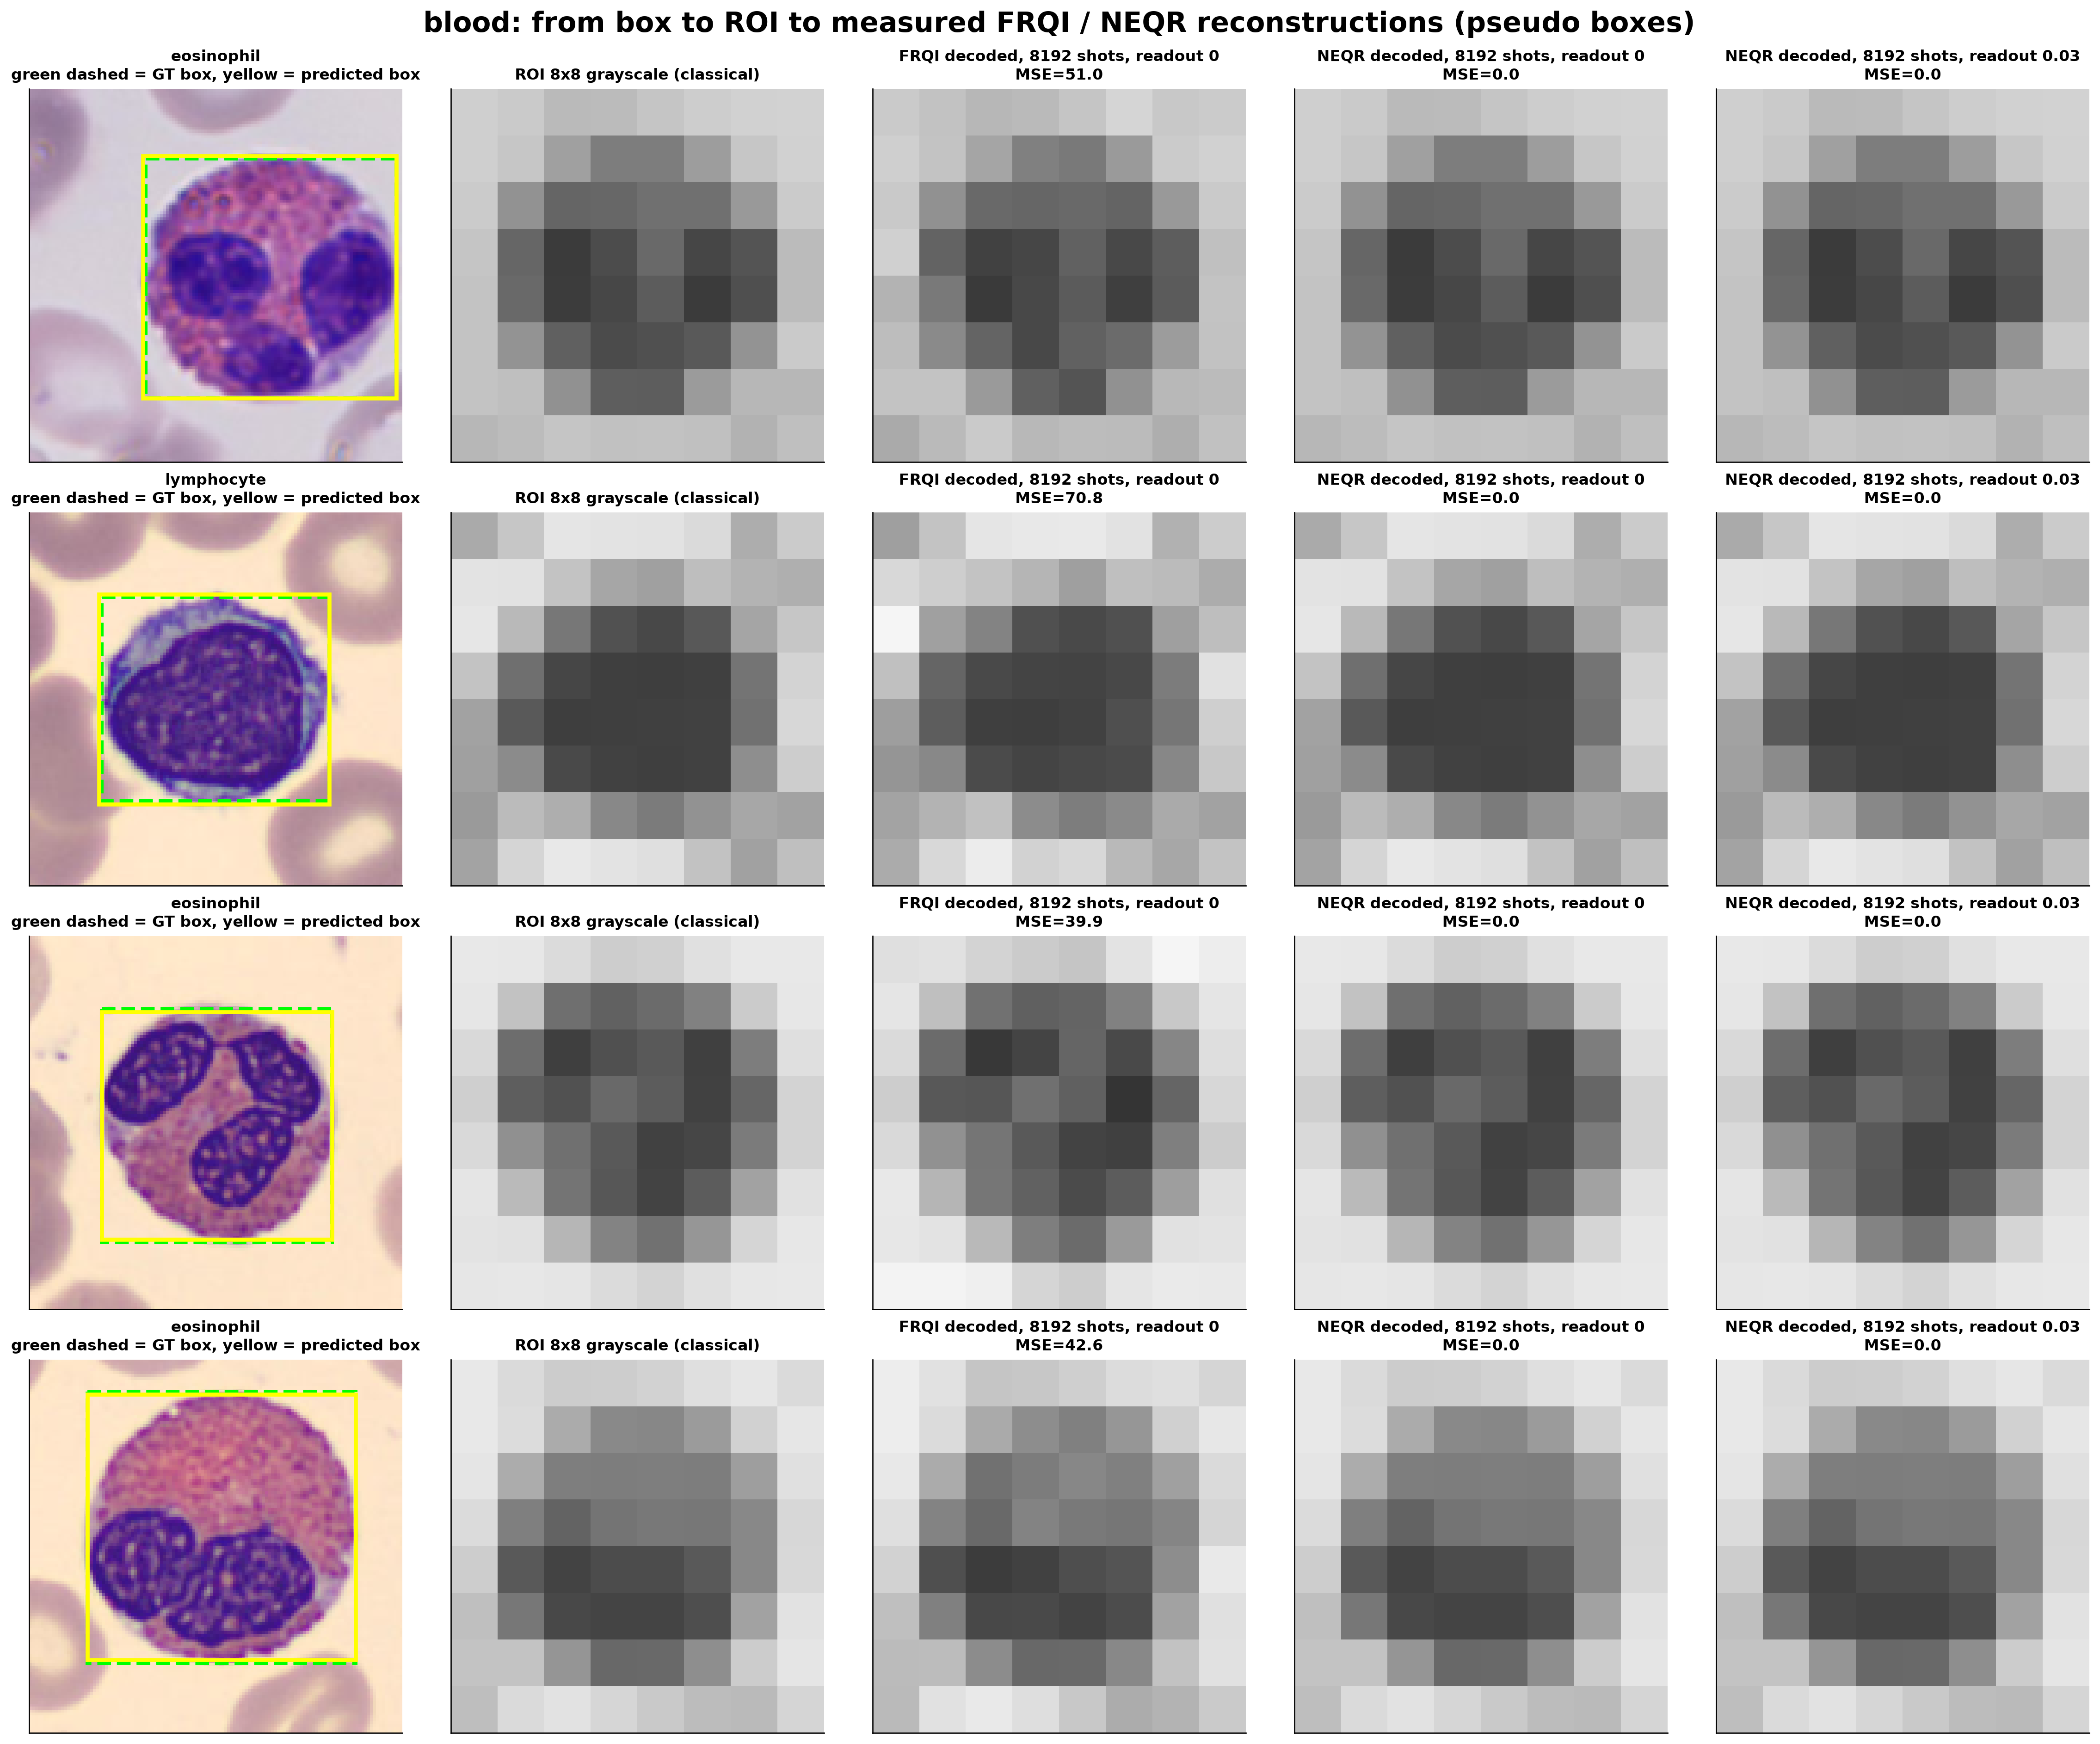

In [71]:
for key, d in DATASETS_Q.items():
    raw = d["raw"]; test_ids = d["idx"]["test"]; ok = [i for i in test_ids if raw["has_mask"][i]][:4]
    if not ok:
        continue
    rng_v = np.random.default_rng(SEED)
    fig, axes = plt.subplots(len(ok), 5, figsize=(19, 3.9 * len(ok)), constrained_layout=True, squeeze=False)
    for r, i in enumerate(ok):
        gt_box = tuple(int(v) for v in raw["boxes"][i]); pred_box = d["pred_lookup"].get(str(raw["sample_id"][i]))
        axes[r, 0].imshow(raw["images"][i]); axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
        x0, y0, x1, y1 = gt_box; axes[r, 0].add_patch(Rectangle((x0 - .5, y0 - .5), x1 - x0, y1 - y0, fill=False, edgecolor="lime", linewidth=2.4, linestyle="--"))
        if pred_box is not None and pred_box[0] >= 0:
            x0, y0, x1, y1 = pred_box; axes[r, 0].add_patch(Rectangle((x0 - .5, y0 - .5), x1 - x0, y1 - y0, fill=False, edgecolor="yellow", linewidth=2.6))
        axes[r, 0].set_title(f"{d['class_names'][int(raw['labels'][i])].split('(')[0].strip()[:22]}\ngreen dashed = GT box, yellow = predicted box", fontsize=10)
        crop, _ = square_crop(raw["images"][i], pred_box if (pred_box is not None and pred_box[0] >= 0) else gt_box)
        roi = to_gray_uint8(crop, sweep_res)
        axes[r, 1].imshow(roi, cmap="gray", vmin=0, vmax=255, interpolation="nearest"); axes[r, 1].set_title(f"ROI {sweep_res}x{sweep_res} grayscale (classical)", fontsize=10)
        panels = [("FRQI", MAIN_SHOTS, 0.0), ("NEQR", MAIN_SHOTS, 0.0), ("NEQR", MAIN_SHOTS, max(READOUT_SWEEP))]
        for c, (enc, shots, readout) in enumerate(panels):
            counts = sample_counts(roi, enc, shots, readout, rng_v)
            dec, unobs = (decode_frqi_counts if enc == "FRQI" else decode_neqr_counts)(counts, sweep_res)
            axes[r, 2 + c].imshow(dec, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
            axes[r, 2 + c].set_title(f"{enc} decoded, {shots} shots, readout {readout:g}\nMSE={np.mean((dec.astype(float) - roi) ** 2):.1f}", fontsize=10)
        for a in axes[r, 1:]:
            a.set_xticks([]); a.set_yticks([])
    fig.suptitle(f"{key}: from box to ROI to measured FRQI / NEQR reconstructions" + (" (pseudo boxes)" if key == "blood" else "")); save_fig(fig, f"{key}_roi_encoding_examples"); plt.show()

In [72]:
resource_by_enc = {}
if circuit_rows:
    cdf = pd.DataFrame(circuit_rows)
    if "compiled_cx" in cdf:
        resource_by_enc = cdf[cdf["status"] == "measured"].groupby(["image_size", "encoding"])[["logical_qubits", "compiled_cx", "compiled_depth"]].mean().to_dict("index")

rows = []
for r in done[(done["classifier"] == "logreg") & (done["feature_family"].isin(["decoded", "pixels"]))].groupby(
        ["dataset", "resolution", "roi_test_source", "encoding"]).agg(
        n_train=("n_train", "first"), n_test=("n_test", "first"), accuracy=("accuracy", "mean"), macro_f1=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"),
        roc_auc=("roc_auc_ovr_macro", "mean"), n_seeds=("seed", "nunique")).reset_index().itertuples(index=False):
    res_info = resource_by_enc.get((r.resolution, r.encoding), {})
    rows.append({"dataset": r.dataset, "method": "hybrid: encode -> measure -> logistic regression" if r.encoding in ("FRQI", "NEQR") else "classical pixels -> logistic regression",
                 "representation": r.encoding, "roi_source": r.roi_test_source, "resolution": f"{r.resolution}x{r.resolution}", "n_train": r.n_train, "n_test": r.n_test,
                 "accuracy": r.accuracy, "macro_f1": r.macro_f1, "macro_f1_std": r.macro_f1_std, "roc_auc": r.roc_auc,
                 "qubits": res_info.get("logical_qubits", np.nan), "cx_gates_compiled": res_info.get("compiled_cx", np.nan), "depth_compiled": res_info.get("compiled_depth", np.nan),
                 "mode": "Born-sampling simulation, shots=%d" % MAIN_SHOTS if r.encoding in ("FRQI", "NEQR") else "classical CPU", "n_seeds": r.n_seeds, "status": "completed"})
for item in NOT_RUN:
    rows.append({"dataset": "-", "method": item["item"], "status": "not_run", "notes": item["reason"]})
final_table = pd.DataFrame(rows)
display(final_table.round(4))
final_table.to_csv(RESULTS_DIR / "comparison_table.csv", index=False)
pd.DataFrame(NOT_RUN).to_csv(RESULTS_DIR / "not_run.csv", index=False)

,dataset,method,representation,roi_source,resolution,n_train,n_test,accuracy,macro_f1,macro_f1_std,roc_auc,qubits,cx_gates_compiled,depth_compiled,mode,n_seeds,status
0,blood,hybrid: encode -> measure -> logistic regression,FRQI,full_image,4x4,500,300,0.5200,0.5084,NaN,0.8816,5.0,1152.0,2049.0,"Born-sampling simulation, shots=8192",1,completed
1,blood,hybrid: encode -> measure -> logistic regression,NEQR,full_image,4x4,500,300,0.5200,0.5074,NaN,0.8853,12.0,1355.6,2583.4,"Born-sampling simulation, shots=8192",1,completed
2,blood,classical pixels -> logistic regression,classical_gray,full_image,4x4,500,300,0.5233,0.5099,NaN,0.8837,NaN,NaN,NaN,classical CPU,1,completed
3,blood,classical pixels -> logistic regression,classical_rgb,full_image,4x4,500,300,0.8067,0.7868,NaN,0.9577,NaN,NaN,NaN,classical CPU,1,completed
4,blood,hybrid: encode -> measure -> logistic regression,FRQI,gt_box,4x4,500,300,0.3867,0.3343,NaN,0.7881,5.0,1152.0,2049.0,"Born-sampling simulation, shots=8192",1,completed
5,blood,hybrid: encode -> measure -> logistic regression,NEQR,gt_box,4x4,500,300,0.4167,0.3883,NaN,0.8032,12.0,1355.6,2583.4,"Born-sampling simulation, shots=8192",1,completed
6,blood,classical pixels -> logistic regression,classical_gray,gt_box,4x4,500,300,0.4167,0.3883,NaN,0.8032,NaN,NaN,NaN,classical CPU,1,completed
7,blood,classical pixels -> logistic regression,classical_rgb,gt_box,4x4,500,300,0.6967,0.6927,NaN,0.9376,NaN,NaN,NaN,classical CPU,1,completed
8,blood,hybrid: encode -> measure -> logistic regression,FRQI,pred_box,4x4,500,300,0.3400,0.3253,NaN,0.7694,5.0,1152.0,2049.0,"Born-sampling simulation, shots=8192",1,completed
9,blood,hybrid: encode -> measure -> logistic regression,NEQR,pred_box,4x4,500,300,0.3333,0.3141,NaN,0.7695,12.0,1355.6,2583.4,"Born-sampling simulation, shots=8192",1,completed


In [73]:
SEG_RESULTS = PROJECT_DIR / f"results_seg_{'full' if RUN_MODE == 'paper' else RUN_MODE}" / "results_summary_by_experiment.csv"
if SEG_RESULTS.exists():
    print("Reference - classical U-Net results from the segmentation notebook (same run mode), full-image classification head:")
    display(pd.read_csv(SEG_RESULTS)[["dataset", "experiment", "macro_f1_mean", "macro_f1_std", "balanced_accuracy_mean", "box_iou_mean_mean"]].round(4))

manifest = {
    "project": "Quantum ROI encoding (FRQI vs NEQR) on regions found by a segmentation model", "run_mode": RUN_MODE, "seed": SEED, "q_config": Q_CONFIG,
    "resolutions": RES_LIST, "main_shots": MAIN_SHOTS, "shots_sweep": SHOTS_SWEEP, "readout_sweep": READOUT_SWEEP, "roi_margin": ROI_MARGIN,
    "feature_families": FEATURE_FAMILIES, "classifiers": MAIN_CLASSIFIERS, "datasets": {k: {s: int(len(i)) for s, i in d["idx"].items()} for k, d in DATASETS_Q.items()},
    "predicted_box_provenance": {k: d["pred_meta"] for k, d in DATASETS_Q.items()},
    "simulation": "finite-shot Born sampling of exact FRQI/NEQR state probabilities + exact classical readout-error channel; circuits verified on a few real ROI images with Qiskit",
    "qiskit": QISKIT_VERSION, "aer_available": AER_OK, "versions": {"python": platform.python_version(), "numpy": np.__version__},
    "limitations": [
        "No quantum hardware; no gate noise; readout error is an idealised symmetric bit-flip channel.",
        "FRQI/NEQR encode only the downsampled grayscale ROI, so the classical pixel control bounds what the quantum pipeline can achieve at that resolution.",
        "Blood masks/boxes are heuristic pseudo-labels; predicted boxes inherit that limitation.",
        "Smoke-mode numbers are not results; few seeds, descriptive statistics only, no multiple-comparison correction.",
        "Quantum advantage is not claimed or tested."],
}
(RESULTS_DIR / "experiment_manifest.json").write_text(json.dumps(manifest, indent=2, default=str), encoding="utf-8")

Reference - classical U-Net results from the segmentation notebook (same run mode), full-image classification head:


,dataset,experiment,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,box_iou_mean_mean
0,blood,cls_only,0.5885,NaN,0.6343,NaN
1,blood,multitask,0.5845,NaN,0.6030,0.8891
2,blood,seg_only,NaN,NaN,NaN,0.8245
3,derma,cls_only,0.2957,NaN,0.3185,NaN
4,derma,multitask,0.2671,NaN,0.3444,0.6509
5,derma,seg_only,NaN,NaN,NaN,0.7326


2288

In [74]:
lines = ["# Quantum ROI experiment summary (generated from result files)", "", f"- run mode: **{RUN_MODE}**", f"- Qiskit: {QISKIT_VERSION}", ""]
for csv_name in ("main_matrix_summary.csv", "paired_bootstrap_comparisons.csv", "shot_readout_sweep_summary.csv", "not_run.csv"):
    path = RESULTS_DIR / csv_name
    if path.exists() and path.stat().st_size > 5:
        frame = pd.read_csv(path)
        frame = frame.apply(lambda col: col.map(lambda v: f"{v:.4g}" if isinstance(v, float) and not pd.isna(v) else ("" if pd.isna(v) else str(v))))
        lines += [f"## {csv_name}", "", "| " + " | ".join(frame.columns) + " |", "| " + " | ".join("---" for _ in frame.columns) + " |"]
        lines += ["| " + " | ".join(row) + " |" for row in frame.head(80).itertuples(index=False)] + [""]
lines += ["## Limitations", ""] + [f"- {t}" for t in manifest["limitations"]]
(RESULTS_DIR / "summary.md").write_text("\n".join(lines), encoding="utf-8")
inventory = pd.DataFrame([{"file": str(p.relative_to(RESULTS_DIR)), "KB": round(p.stat().st_size / 1024, 1)} for p in sorted(RESULTS_DIR.rglob("*")) if p.is_file()])
display(inventory); inventory.to_csv(RESULTS_DIR / "artifact_inventory.csv", index=False)
print("Wrote results to", RESULTS_DIR.resolve())

,file,KB
0,aer_noise_crosscheck.csv,0.5
1,artifact_inventory.csv,2.0
2,circuit_verification_and_resources.csv,2.9
3,comparison_table.csv,8.9
4,experiment_manifest.json,2.3
5,figures\blood_main_comparison.pdf,23.8
6,figures\blood_main_comparison.png,162.4
7,figures\blood_noise_degradation.pdf,24.2
8,figures\blood_noise_degradation.png,149.9
9,figures\blood_roi_encoding_examples.pdf,332.7


Wrote results to C:\Users\sripo\OneDrive\Desktop\Hybrid_QIP\results_quantum_smoke


In [75]:
PAPER_DIR = RESULTS_DIR / "paper_tables"; PAPER_DIR.mkdir(exist_ok=True)
for name in ("circuit_verification_and_resources.csv", "aer_shot_check.csv", "main_matrix_summary.csv", "paired_bootstrap_comparisons.csv", "shot_readout_sweep_summary.csv",
             "vqc_summary.csv", "vqc_paired_comparisons.csv", "fusion_with_cnn.csv", "noise_robustness.csv", "aer_noise_crosscheck.csv", "not_run.csv"):
    if (RESULTS_DIR / name).exists(): shutil_copy = (RESULTS_DIR / name).read_bytes(); (PAPER_DIR / name).write_bytes(shutil_copy)
print("Tables copied to", PAPER_DIR)
print("\n==================== CLAIM GUARD (generated from your result files) ====================")
if RUN_MODE != "paper": print(f"RUN_MODE = {RUN_MODE}: use 'paper' (all data, 3 seeds) before quoting any number in the manuscript.")
if len(vqc_cmp_df):
    for r in vqc_cmp_df[vqc_cmp_df["comparison"].str.startswith("FRQI - NEQR")].itertuples():
        verdict = "interval excludes 0" if r.interval_excludes_0 else "no detectable difference"
        print(f"- {r.dataset} {r.resolution}x{r.resolution} [{r.roi_test_source}] FRQI-VQC minus NEQR-VQC macro-F1 = {r.mean_diff:+.3f} [{r.ci95_low:+.3f}, {r.ci95_high:+.3f}] -> {verdict}")
    for r in vqc_cmp_df[vqc_cmp_df["comparison"].str.contains("ctrl")].itertuples():
        print(f"- {r.dataset} {r.resolution}x{r.resolution} [{r.roi_test_source}] {r.comparison} = {r.mean_diff:+.3f} [{r.ci95_low:+.3f}, {r.ci95_high:+.3f}] -> " + ("quantum branch differs from width-matched classical control" if r.interval_excludes_0 else "no detectable difference from the classical control"))
if len(fusion_df):
    for r in fusion_df.itertuples():
        print(f"- fusion {r.dataset} {r.resolution}x{r.resolution} {r.branch} [{r.roi_test_source}]: alpha*={r.alpha_selected_on_val:.2f}, macro-F1 {r.cnn_test_macro_f1:.3f} -> {r.fused_test_macro_f1:.3f} (diff {r.macro_f1_diff:+.3f} [{r.ci95_low:+.3f}, {r.ci95_high:+.3f}])")
print("\nNever write: 'quantum advantage', 'outperforms classical', or any clinical-diagnosis wording, unless a row above supports it with an interval that excludes 0 AND the comparison is against a strong classical model.")
print("Items not run (state them in the Limitations section):", pd.DataFrame(NOT_RUN).to_dict("records") if NOT_RUN else "none")

Tables copied to C:\Users\sripo\OneDrive\Desktop\Hybrid_QIP\results_quantum_smoke\paper_tables

==================== CLAIM GUARD (generated from your result files) ====================
RUN_MODE = smoke: use 'paper' (all data, 3 seeds) before quoting any number in the manuscript.
- derma 4x4 [gt_box] FRQI-VQC minus NEQR-VQC macro-F1 = -0.118 [-0.163, -0.070] -> interval excludes 0
- derma 4x4 [pred_box] FRQI-VQC minus NEQR-VQC macro-F1 = -0.129 [-0.183, -0.076] -> interval excludes 0
- blood 4x4 [gt_box] FRQI-VQC minus NEQR-VQC macro-F1 = -0.317 [-0.378, -0.265] -> interval excludes 0
- blood 4x4 [pred_box] FRQI-VQC minus NEQR-VQC macro-F1 = -0.240 [-0.292, -0.187] -> interval excludes 0
- derma 4x4 [gt_box] FRQI - ctrl_FRQI_width (macro-F1) = -0.014 [-0.032, +0.005] -> no detectable difference from the classical control
- derma 4x4 [gt_box] NEQR - ctrl_NEQR_width (macro-F1) = +0.056 [+0.005, +0.108] -> quantum branch differs from width-matched classical control
- derma 4x4 [pred_box] F

In [76]:
from pathlib import Path
import pandas as pd
import numpy as np

In [77]:
audit_files = [
    "main_matrix_summary.csv",
    "paired_bootstrap_comparisons.csv",
    "shot_readout_sweep_summary.csv",
    "vqc_summary.csv",
    "vqc_paired_comparisons.csv",
    "noise_robustness_completed.csv",
    "aer_noise_crosscheck.csv",
    "circuit_verification_and_resources.csv",
]
audit_rows = []
for fname in audit_files:
    p = RESULTS_DIR / fname
    if not p.exists():
        audit_rows.append({"file": fname, "status": "MISSING", "rows": 0, "columns": "", "notes": "Run the relevant experiment cell."})
        continue
    try:
        frame = pd.read_csv(p)
        status = "OK" if len(frame) else "EMPTY"
        notes = ""
        if "status" in frame.columns:
            bad = frame["status"].astype(str).str.contains("failed|not_run|error", case=False, na=False).sum()
            if bad:
                notes = f"{bad} rows marked failed/not_run"
        audit_rows.append({"file": fname, "status": status, "rows": len(frame), "columns": len(frame.columns), "notes": notes})
    except Exception as exc:
        audit_rows.append({"file": fname, "status": "UNREADABLE", "rows": 0, "columns": "", "notes": str(exc)})

audit_df = pd.DataFrame(audit_rows)
display(audit_df)
print(f"Run mode: {RUN_MODE}")
if RUN_MODE != "paper":
    print("NOT PAPER-READY: current configuration is smoke mode. Do not report these metrics as final research findings.")
else:
    print("Paper mode selected. Still inspect failures, class balance, paired comparisons, confidence intervals, and noise settings before reporting.")

,file,status,rows,columns,notes
0,main_matrix_summary.csv,OK,120,17,
1,paired_bootstrap_comparisons.csv,OK,36,10,
2,shot_readout_sweep_summary.csv,OK,48,10,
3,vqc_summary.csv,OK,16,20,
4,vqc_paired_comparisons.csv,OK,12,10,
5,noise_robustness_completed.csv,OK,32,22,
6,aer_noise_crosscheck.csv,OK,4,9,
7,circuit_verification_and_resources.csv,OK,20,16,


Run mode: smoke
NOT PAPER-READY: current configuration is smoke mode. Do not report these metrics as final research findings.
